<a href="https://colab.research.google.com/github/dherreraal/data_structures/blob/main/Clase_13/13_ED_Heaps_PriorityQueues.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Montículos Binarios (Heaps), Colas de Prioridad y Transición Estructural AVL
### Universidad Nacional de Colombia
#### **Profesor:** David Alberto Herrera Alvarez
#### **Curso:** Estructuras de Datos
---


## Índice de Contenido
1. Motivación y el Tipo de Dato Abstracto (TDA) Cola de Prioridad
2. Implementaciones Inocentes (Naive) y Cuello de Botella Asintótico
3. El Árbol Binario Completo y su Representación Implícita en Memoria
4. La Propiedad de Orden de Montículo (Heap Order Property)
5. Mecánica Algorítmica: Inserción, Extracción y Rebalanceo
6. Demostraciones Prácticas en Java
7. Comparativa Estructural (Árbol AVL vs. Montículo Binario)
8. Buenas Prácticas y Errores Frecuentes (Pitfalls) en Heaps
9. Ejercicios Prácticos
10. Bibliografía y Referencias
---


## 1. Motivación y el Tipo de Dato Abstracto (TDA) Cola de Prioridad

### 1.1 Limitaciones del Modelo FIFO Tradicional frente a la Realidad Computacional
En los primeros cursos de programación y estructuras lineales, se introduce la **Cola Estándar (Queue)** bajo la disciplina estricta **FIFO (*First-In, First-Out*)**: el primer elemento en ingresar mediante `PushBack(e)` es invariablemente el primero en salir mediante `PopFront()`.

Sin embargo, los sistemas del mundo real rara vez operan de manera puramente cronológica:
* **Sistemas Operativos y Planificación de Procesos (CPU Scheduling):** Un hilo de renderizado multimedia o un fallo de hardware (*interrupt*) no puede esperar detrás de 500 tareas secundarias por lotes (*batch jobs*).
* **Enrutamiento de Redes IP:** Los paquetes de control de sesión y voz sobre IP (VoIP) requieren prioridad de ancho de banda sobre la descarga de archivos masivos en segundo plano.
* **Triage Médico Hospitalario:** Un paciente que ingresa en paro cardiorrespiratorio debe ser intervenido de inmediato, sin importar cuántas horas lleve esperando una persona con una fractura leve o un chequeo preventivo.

### 1.2 Definición Formal del TDA Cola de Prioridad (*Priority Queue*)
Una **Cola de Prioridad** es una generalización abstracta de una cola donde cada elemento tiene asociado un valor o clave escalar denominado **prioridad ($p$)**. Los elementos son despachados en orden de prioridad y no en su orden cronológico de arribo.

Formalmente, el TDA soporta las siguientes operaciones elementales:
* $\text{Insert}(e, p)$ (o $\text{Push}$): Inserta un elemento $e$ con prioridad asociada $p$ en el conjunto de datos.
* $\text{ExtractMax}()$ (o $\text{ExtractMin}()$ en Min-Heaps): Remueve y retorna el elemento con la máxima prioridad actual.
* $\text{GetMax}()$ (o $\text{Peek}()$): Inspecciona y retorna el elemento de mayor prioridad sin alterar el conjunto de datos ($O(1)$ deseado).

#### Operaciones Dinámicas Adicionales:
* $\text{ChangePriority}(it, p')$: Modifica la prioridad del elemento referenciado por el iterador/índice $it$ a un nuevo valor $p'$.
* $\text{Remove}(it)$: Elimina un elemento arbitrario identificado por $it$ dentro de la estructura.

### 1.3 Casos de Uso Fundamentales en Computación y Algoritmia Avanzada
Las colas de prioridad constituyen el motor algorítmico detrás de hitos fundamentales de la informática moderna:
1. **Algoritmo de Dijkstra:** Búsqueda del camino más corto en grafos ponderados. La cola de prioridad extrae continuamente el vértice no visitado con la menor distancia acumulada estimada.
2. **Algoritmo de Prim:** Construcción del Árbol de Expansión Mínima (*Minimum Spanning Tree - MST*) en redes de infraestructura.
3. **Algoritmo de Huffman:** Compresión óptima de datos y códigos de longitud variable sin prefijos (utilizado en JPEG, MP3 y GZIP). Extrae reiteradamente los dos símbolos de menor frecuencia estadística para fusionarlos.
4. **Simulación Basada en Eventos Discretos:** Los motores de física y telecomunicaciones procesan eventos futuros ordenados estrictamente por su marca de tiempo (*timestamp* de simulación).


## 2. Implementaciones Inocentes (*Naive*) y el Cuello de Botella Asintótico

Para comprender por qué el **Montículo Binario (*Binary Heap*)** representa uno de los diseños más elegantes de la ingeniería de datos, es instructivo analizar primero cómo responderían las estructuras secuenciales estándar (arreglos y listas enlazadas) ante los requerimientos de una Cola de Prioridad.

<div align="center">
  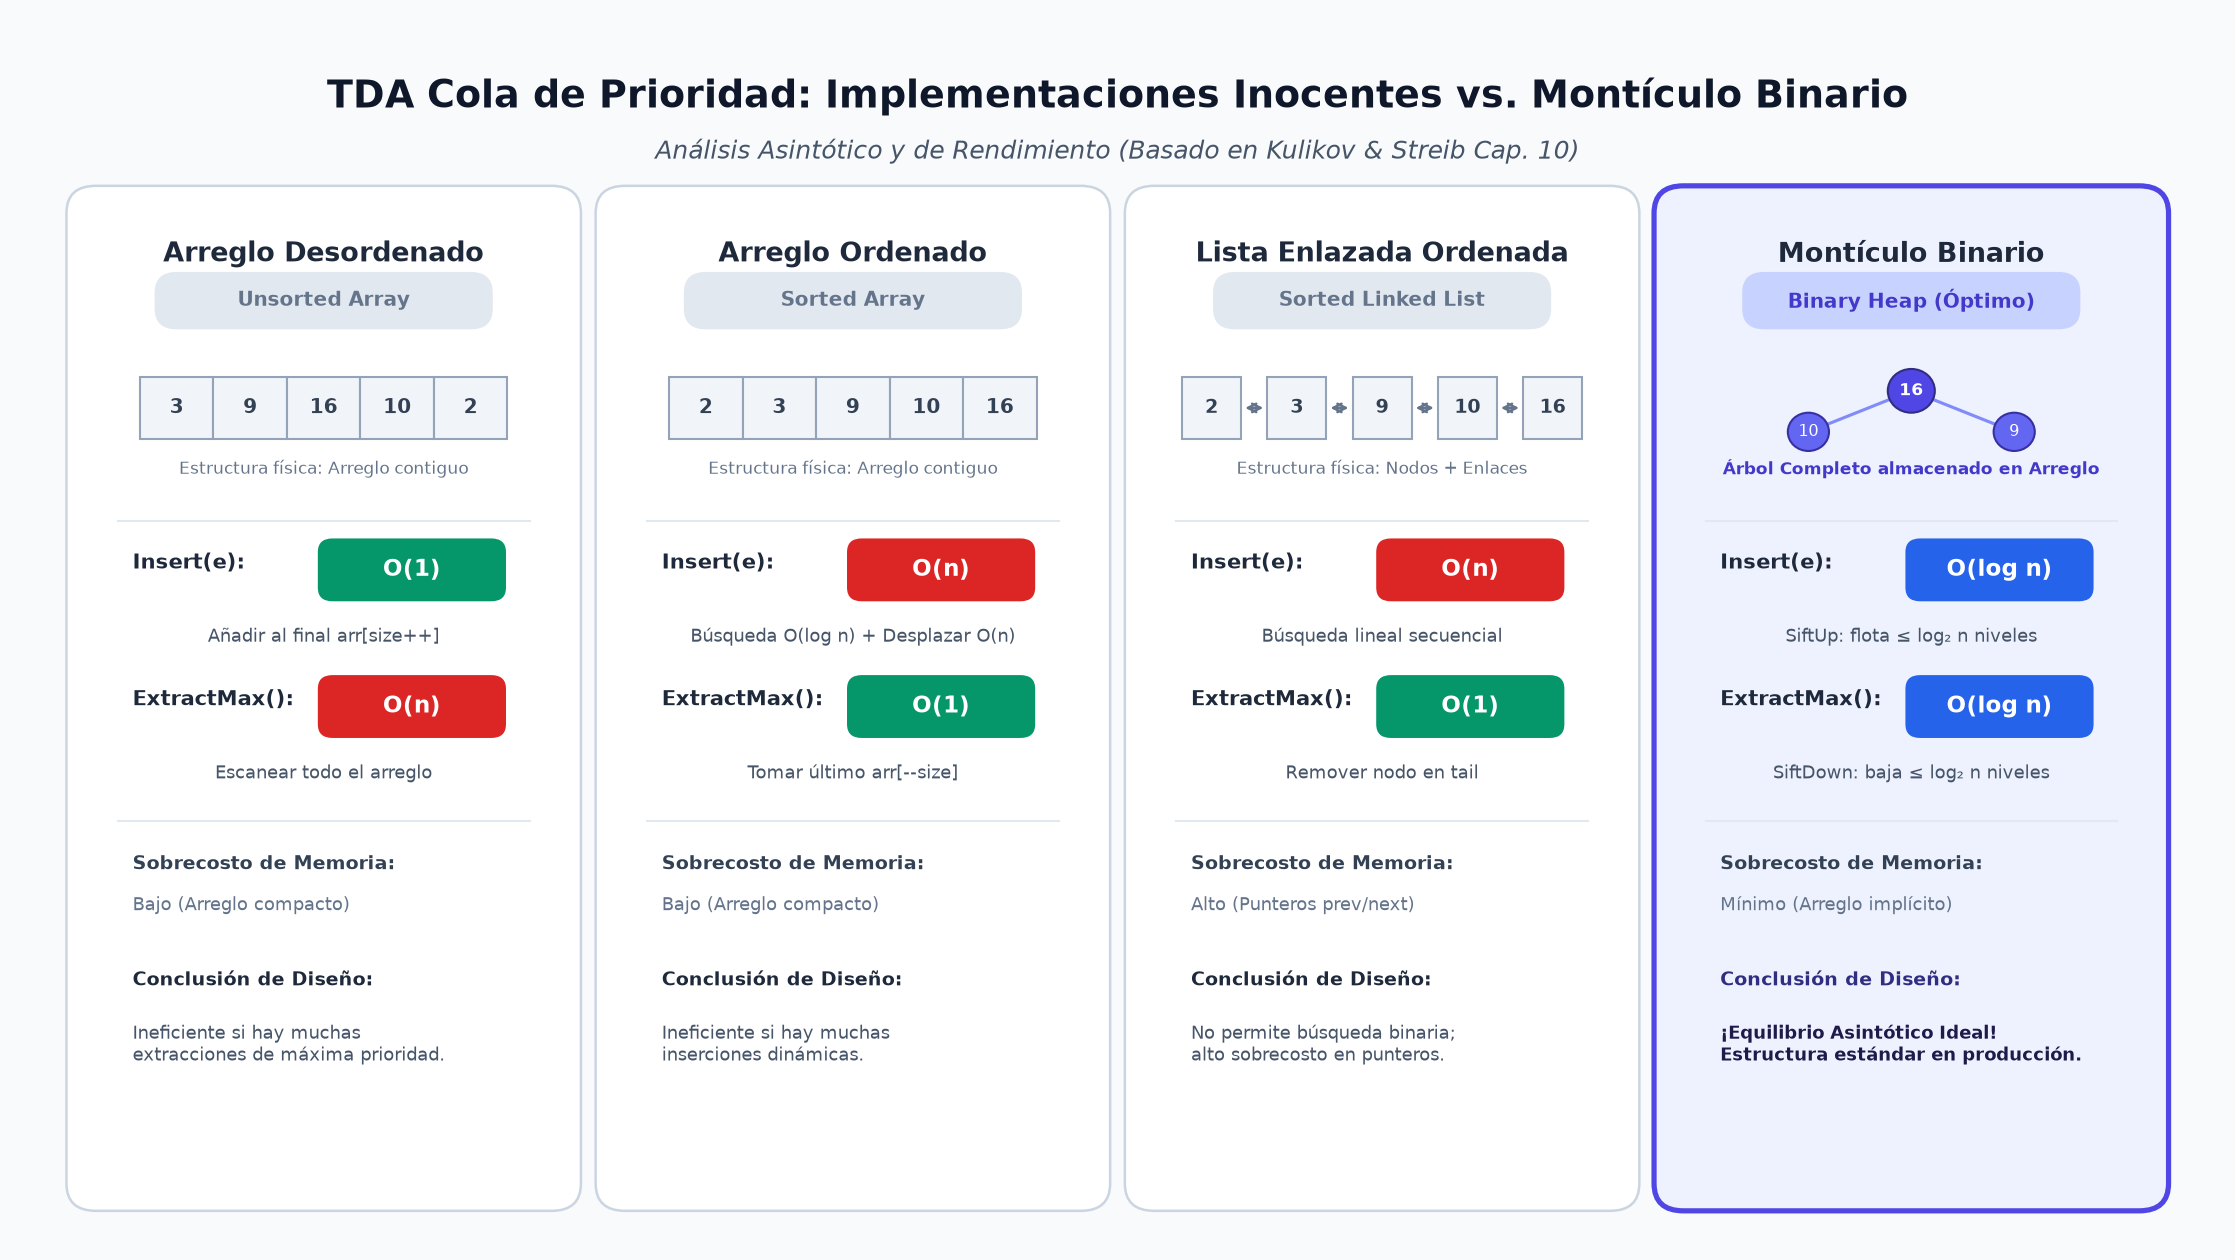
  <p><em>Figura 1: Comparativa del TDA Cola de Prioridad entre Implementaciones Inocentes y el Montículo Binario.</em></p>
</div>

### 2.1 Arreglo y Lista Desordenada: Inserción Inmediata vs. Extracción Costosa
Si almacenamos los elementos conforme van llegando sin mantener ningún criterio de orden interno:
* **Inserción (`Insert`):** Se añade el nuevo elemento al final del arreglo contiguo (`arr[size++] = e`) o en la cabeza/cola de una lista enlazada. Esta operación toma tiempo estrictamente **$O(1)$**.
* **Extracción (`ExtractMax`):** Como los datos están dispersos sin orden, es obligatorio **escanear secuencialmente los $n$ elementos** para identificar cuál de todos posee la mayor prioridad. Tras hallarlo, en un arreglo se reemplaza por el último elemento para evitar huecos, requiriendo un tiempo asintótico de **$O(n)$**.

> **Consecuencia:** En un sistema de streaming o procesamiento de eventos con millones de operaciones, realizar extracciones en $O(n)$ resulta inaceptable (para $10^6$ elementos, cada extracción evalúa un millón de comparaciones).

### 2.2 Arreglo y Lista Ordenada: Extracción Inmediata vs. Inserción Costosa
Si decidimos mantener los elementos ordenados en todo momento (por ejemplo, en orden ascendente):
* **Extracción (`ExtractMax`):** El elemento con mayor prioridad reside siempre en la última posición del arreglo (`arr[--size]`) o en el extremo `tail` de una lista doblemente enlazada. Su consulta y remoción toman tiempo **$O(1)$**.
* **Inserción (`Insert`):**
  * En un **Arreglo Ordenado**: Podemos emplear búsqueda binaria (*Binary Search*) para encontrar la posición correcta en tiempo $O(\log n)$. No obstante, para abrir espacio e insertar el nuevo elemento, debemos **desplazar hacia la derecha** en promedio la mitad del arreglo, lo que impone un costo temporal ineludible de **$O(n)$**.
  * En una **Lista Enlazada Ordenada**: La inserción física del nodo mediante punteros toma $O(1)$, pero la búsqueda de su posición exacta requiere un recorrido secuencial no indexable de **$O(n)$**.

### 2.3 Matriz de Comparación Asintótica: El Dilema de la Eficiencia

| Estructura Subyacente | Inserción (`Insert`) | Extracción de Máximo (`ExtractMax`) | Consulta de Máximo (`GetMax`) |
| :--- | :---: | :---: | :---: |
| **Arreglo Desordenado** | $O(1)$ | $O(n)$ | $O(n)$ |
| **Lista Enlazada Desordenada** | $O(1)$ | $O(n)$ | $O(n)$ |
| **Arreglo Ordenado** | $O(n)$ | $O(1)$ | $O(1)$ |
| **Lista Enlazada Ordenada** | $O(n)$ | $O(1)$ | $O(1)$ |
| **Montículo Binario (*Binary Heap*)** | $O(\log n)$ | $O(\log n)$ | $O(1)$ |

Como demostró Alexander S. Kulikov en sus lecciones fundamentales, ninguna de las alternativas inocentes logra un equilibrio simétrico: una operación es veloz a costa de penalizar linealmente la otra. El **Montículo Binario** rompe este compromiso ofreciendo un costo logarítmico óptimo $O(\log n)$ en ambas operaciones críticas y consulta instantánea $O(1)$.


## 3. El Árbol Binario Completo y su Representación Implícita en Memoria

### 3.1 La Propiedad de Forma (*Shape Property*): Empaquetamiento Secuencial
Un **Árbol Binario Completo (*Complete Binary Tree*)** es un árbol binario en el cual:
1. Todos los niveles hasta la profundidad $h - 1$ se encuentran completamente llenos.
2. En el nivel más profundo ($h$), todos los nodos hoja se encuentran empaquetados consecutivamente **de izquierda a derecha**, sin huecos ni ramificaciones saltadas.

Gracias a esta estricta propiedad geométrica, **no es necesario almacenar nodos con punteros o referencias en memoria dinámica** (como sí lo requieren los BST y los árboles AVL). En su lugar, el árbol completo se mapea de forma biunívoca en un **arreglo secuencial contiguo en memoria RAM**.

<div align="center">
  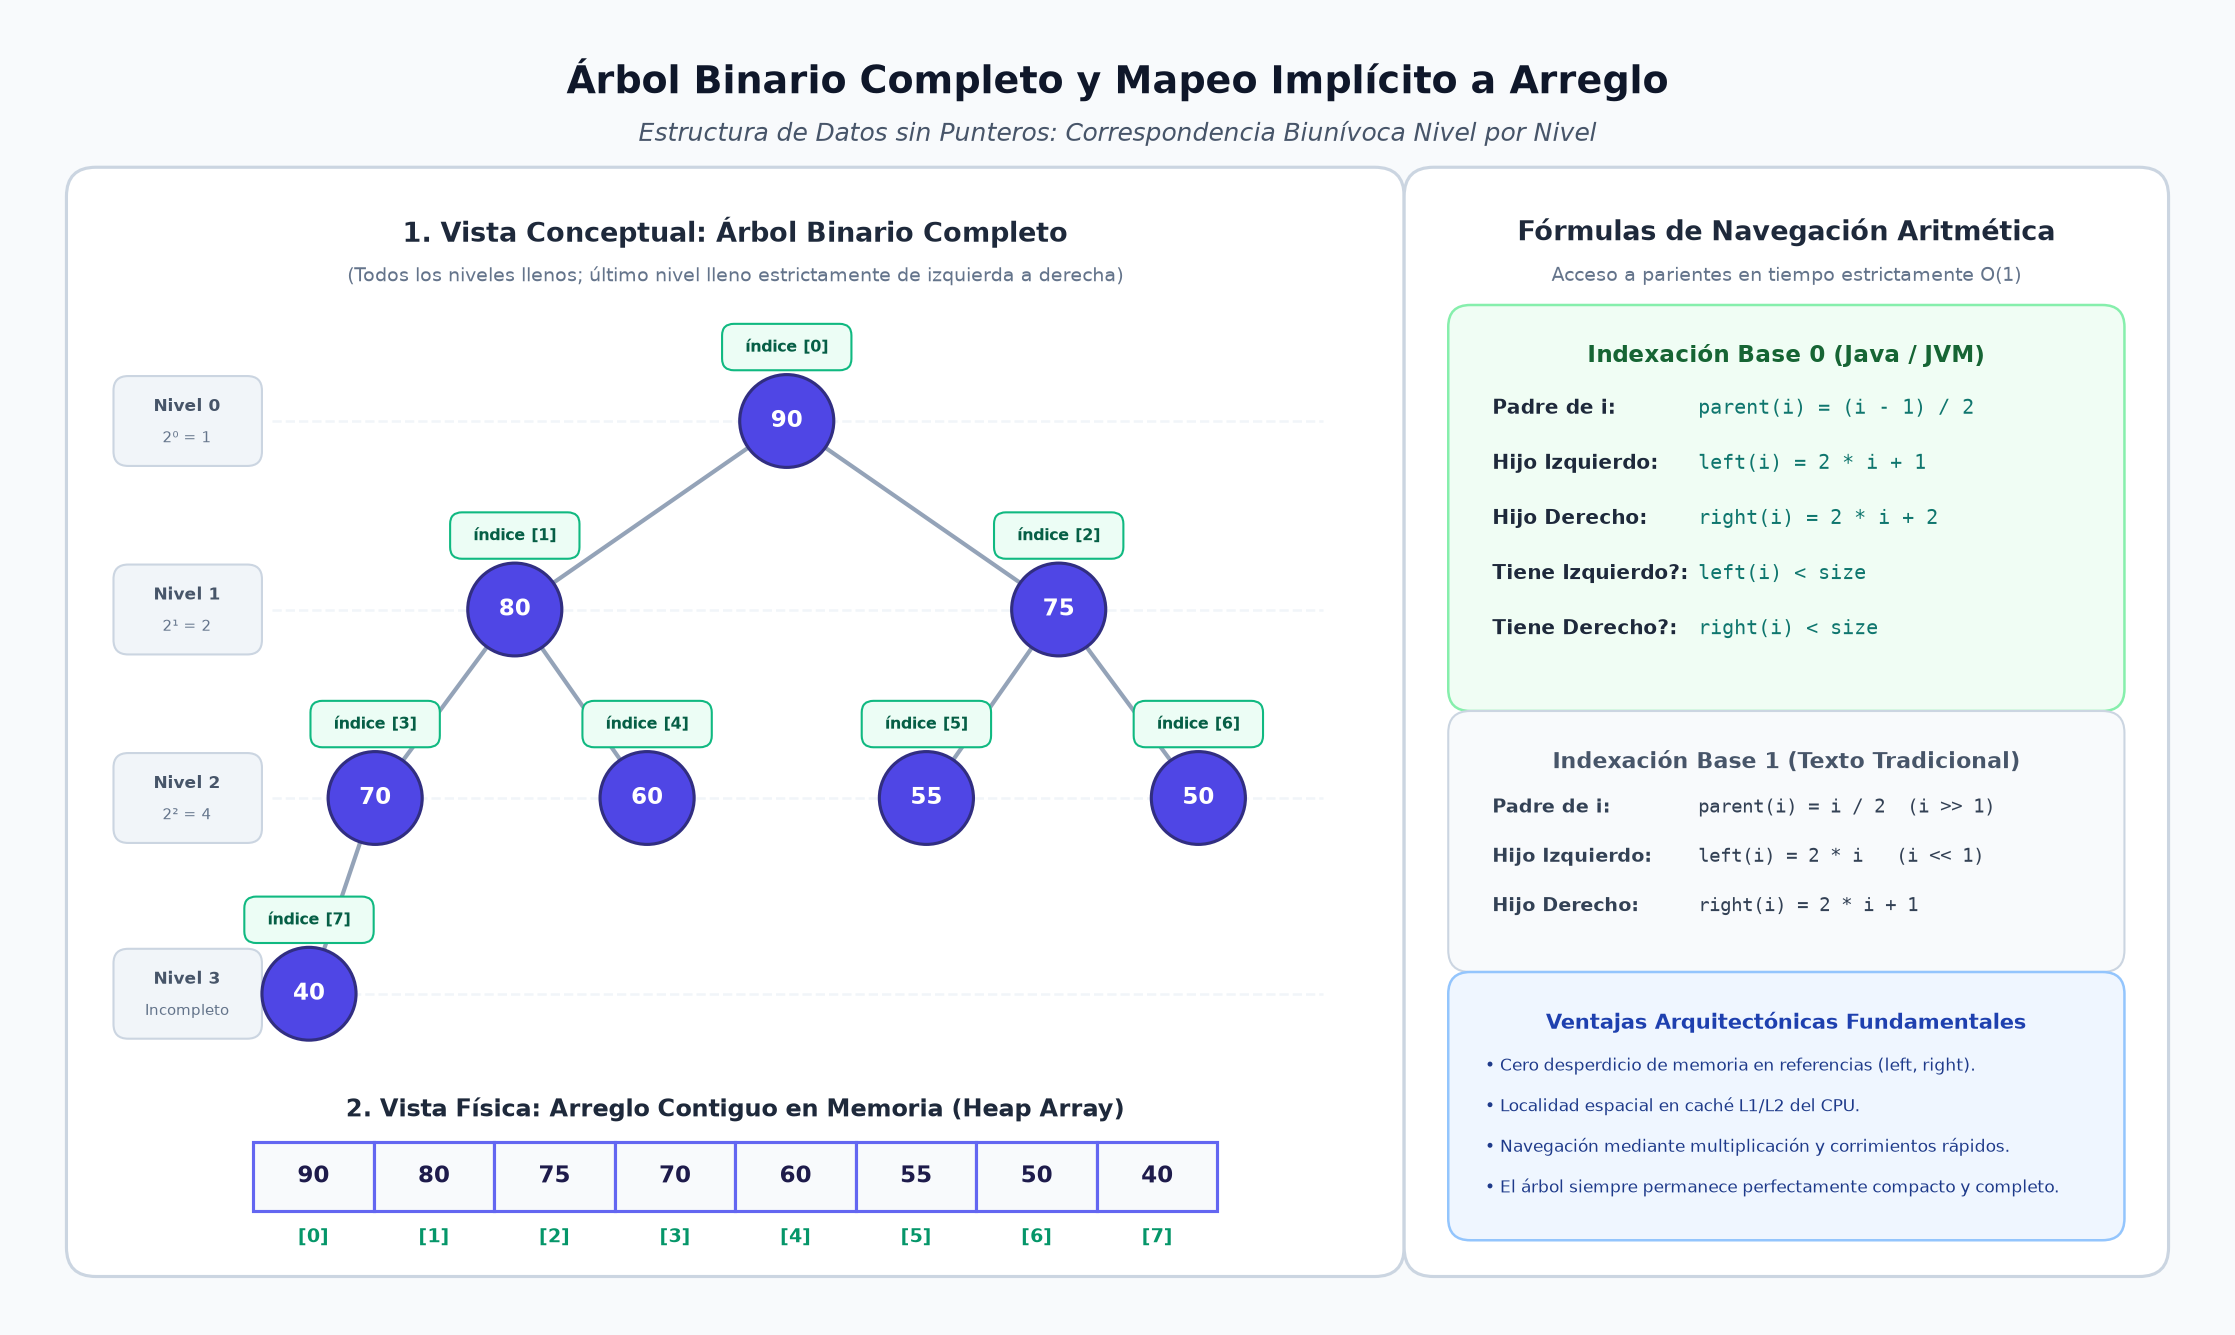
  <p><em>Figura 2: Árbol Binario Completo y su Correspondencia Aritmética Biunívoca en un Arreglo Contiguo.</em></p>
</div>

### 3.2 Aritmética de Índices: Mapeo Biunívoco en Base 0 y Base 1

#### A. Indexación en Base 0 (Estándar en Java, Python, C y C++)
Cuando la raíz del árbol se aloja en el índice `0` del arreglo:
* **Padre de un nodo en el índice $i$:**
  $$\text{parent}(i) = \left\lfloor \frac{i - 1}{2} \right\rfloor$$
* **Hijo Izquierdo de un nodo en el índice $i$:**
  $$\text{leftChild}(i) = 2i + 1$$
* **Hijo Derecho de un nodo en el índice $i$:**
  $$\text{rightChild}(i) = 2i + 2$$
* **Condición de Existencia:**
  * Tiene hijo izquierdo si y solo si: $\text{leftChild}(i) < \text{size}$
  * Tiene hijo derecho si y solo si: $\text{rightChild}(i) < \text{size}$

#### B. Indexación en Base 1 (Tradición en Libros Clásicos de Algoritmos como CLRS)
Cuando la posición `0` se deja libre y la raíz se aloja en el índice `1`:
* **Padre:** $\text{parent}(i) = \lfloor i / 2 \rfloor$ (en operaciones de bits: `i >> 1`)
* **Hijo Izquierdo:** $\text{leftChild}(i) = 2i$ (en operaciones de bits: `i << 1`)
* **Hijo Derecho:** $\text{rightChild}(i) = 2i + 1$ (en operaciones de bits: `(i << 1) | 1`)

### 3.3 Ventajas de Hardware: Localidad de Caché L1/L2 y Supresión de Punteros
La representación implícita en un arreglo plano otorga ventajas colosales a nivel de arquitectura de computadores:
1. **Sobrecosto de Memoria Cero en Referencias:** En arquitecturas de 64 bits, cada puntero `left` y `right` ocupa 8 bytes (16 bytes por nodo). Si sumamos la cabecera de objeto de la JVM (*Object Header* de 12 a 16 bytes), un nodo individual en un árbol enlazado desperdicia entre 32 y 48 bytes solo en infraestructura. En un Heap, el costo estructural adicional por elemento es exactamente **0 bytes**.
2. **Localidad Espacial y Explotación de la Caché L1/L2:** El procesador transfiere bloques contiguos de memoria principal a las líneas de caché de alta velocidad (*Cache Lines* de 64 bytes). Al recorrer un arreglo contiguo, múltiples parientes e hijos contiguos ya residen precargados en caché, eliminando fallos de memoria (*cache misses*) que ralentizan a los árboles basados en nodos dinámicos.


## 4. La Propiedad de Orden de Montículo (*Heap Order Property*)

Además de la propiedad de forma geométrica (ser un árbol completo), un montículo debe satisfacer una invariante de orden vertical en cada uno de sus nodos.

### 4.1 Max-Heap: La Invariante Ancestral $\text{Padre} \ge \text{Hijos}$
En un **Max-Heap (Montículo de Máximos)**, para todo nodo $i$ distinto de la raíz:
$$\text{heap}[\text{parent}(i)] \ge \text{heap}[i]$$
* **Consecuencia Inmediata:** La raíz del árbol (`heap[0]`) almacena siempre el elemento de **mayor valor absoluto** de toda la estructura.
* Subárboles recursivos: Cada subárbol dentro de un Max-Heap es a su vez un Max-Heap válido.

### 4.2 Min-Heap: La Invariante Ancestral $\text{Padre} \le \text{Hijos}$
En un **Min-Heap (Montículo de Mínimos)**, para todo nodo $i$ distinto de la raíz:
$$\text{heap}[\text{parent}(i)] \le \text{heap}[i]$$
* **Consecuencia Inmediata:** La raíz del árbol (`heap[0]`) almacena siempre el elemento de **menor valor absoluto** de toda la estructura.
* Es la variante nativa implementada en `java.util.PriorityQueue` y utilizada directamente en algoritmos de rutas mínimas (Dijkstra).

### 4.3 Diferencia Estructural con los BST: Ausencia de Orden Horizontal entre Hermanos
Es crucial que el estudiante no confunda un Montículo con un Árbol Binario de Búsqueda (BST):
* **En un BST (Orden Horizontal Total):** Todo elemento en el subárbol izquierdo es estrictamente menor que la raíz, y todo elemento en el subárbol derecho es mayor:
  $$\text{Subárbol Izquierdo} < \text{Raíz} < \text{Subárbol Derecho}$$
* **En un Montículo (Orden Vertical Ancestral):** La relación existe **únicamente entre padres e hijos**.
  $$\text{Padre} \ge \text{Hijo Izquierdo} \quad \text{y} \quad \text{Padre} \ge \text{Hijo Derecho}$$
  **No existe ninguna restricción ni relación de orden entre hermanos ni entre primos.** El hijo izquierdo puede ser mayor, menor o igual que el hijo derecho.

> **Implicación Fundamental:** Como un montículo no posee orden horizontal, **no es posible realizar búsqueda binaria en él**. Encontrar una clave arbitraria dentro de un Heap requiere una búsqueda exhaustiva que toma tiempo lineal **$O(n)$**.


## 5. Mecánica Algorítmica: Inserción, Extracción y Rebalanceo

El mantenimiento de las dos propiedades del Heap (Forma Completa y Orden Vertical) se logra mediante dos procedimientos algorítmicos simétricos: **SiftUp** y **SiftDown**.

### 5.1 Inserción y Flotación: El Algoritmo `SiftUp` (*Percolate Up / Move Up*) en $O(\log n)$
Cuando un nuevo elemento $x$ ingresa al montículo:
1. **Preservar la Forma:** Se coloca $x$ en la primera posición libre disponible al final del arreglo (`heap[size] = x`) e incrementamos `size`. Esto garantiza que el árbol siga siendo completo.
2. **Restaurar el Orden (Flotación):** Si $x$ viola la propiedad de montículo con respecto a su padre ($\text{heap}[i] > \text{heap}[\text{parent}(i)]$ en Max-Heap), se realiza un intercambio (*swap*) entre ambos.
3. Se repite la comparación hacia arriba hasta que el padre sea mayor o igual que $x$, o hasta que $x$ alcance la raíz del árbol (`i == 0`).

<div align="center">
  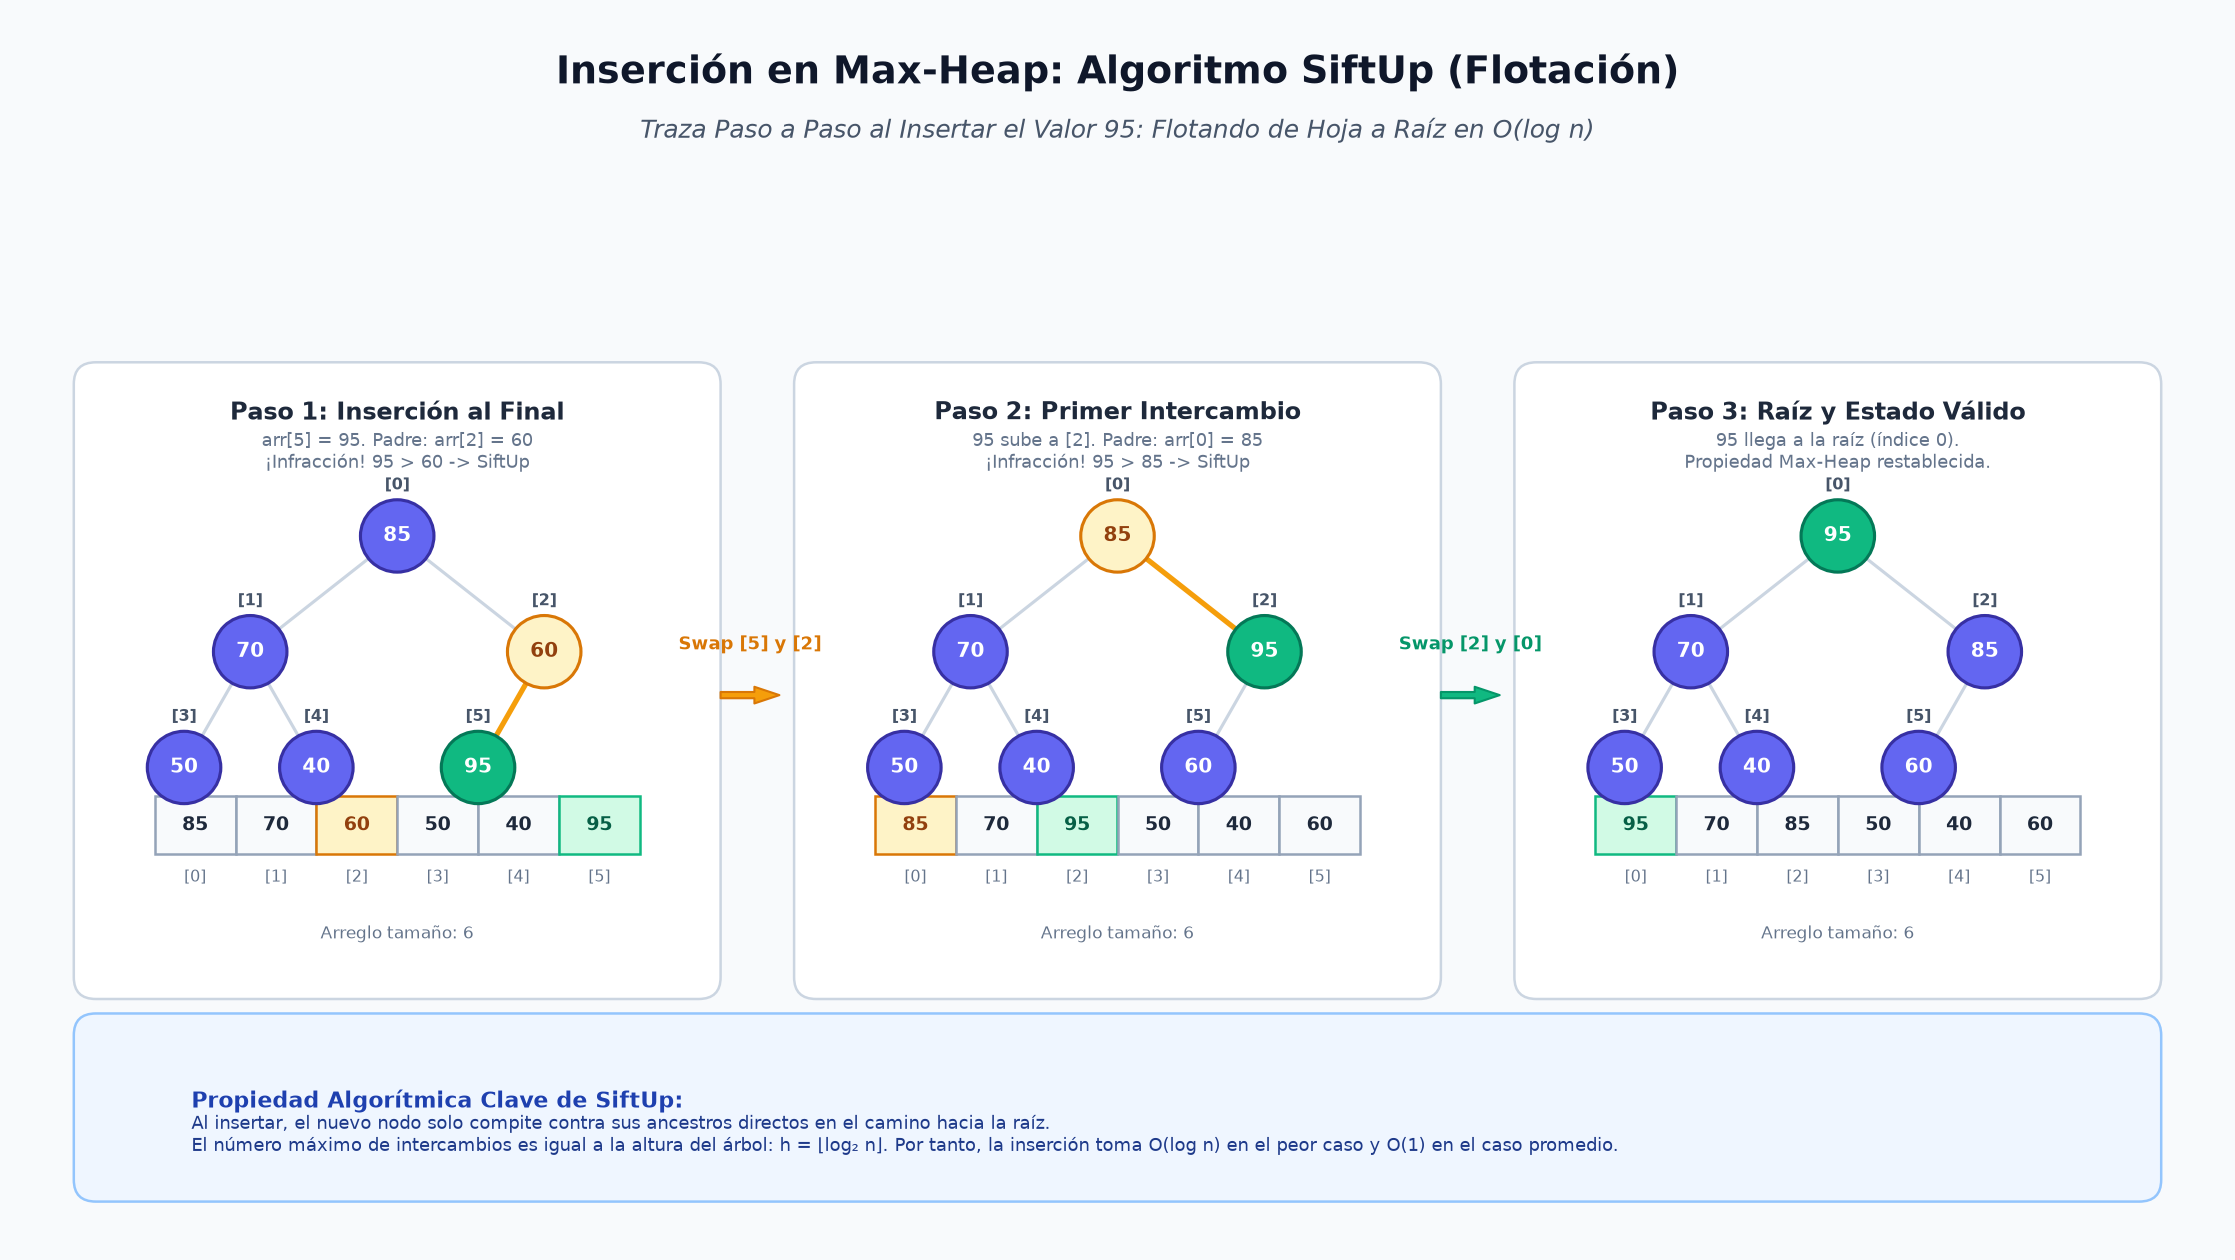
  <p><em>Figura 3: Mecánica de Inserción y Flotación SiftUp paso a paso al ingresar el valor 95.</em></p>
</div>

### 5.2 Extracción de Raíz y Hundimiento: El Algoritmo `SiftDown` (*Percolate Down / Move Down*) en $O(\log n)$
Cuando se solicita extraer el elemento extremo mediante `ExtractMax()`:
1. **Salvar el Resultado:** Guardamos el valor de la raíz (`resultado = heap[0]`).
2. **Preservar la Forma:** Tomamos el **último elemento** del arreglo (`heap[size - 1]`) y lo trasladamos a la raíz (`heap[0]`), decrementando el tamaño en 1 (`size--`). El árbol sigue siendo completo, pero la raíz viola casi con certeza la propiedad de orden.
3. **Restaurar el Orden (Hundimiento):**
   * Identificamos a los dos hijos del nodo actual: $\text{left} = 2i + 1$ y $\text{right} = 2i + 2$.
   * **Regla de Oro:** Se debe seleccionar al **HIJO CON MAYOR PRIORIDAD** (el mayor de los dos en Max-Heap, o el menor en Min-Heap).
   * Si dicho hijo prioritario supera al padre, se intercambian y el proceso continúa descendiendo.
   * Si el nodo actual ya es mayor o igual que ambos hijos, o si alcanza una posición de hoja (sin hijos dentro de los límites de `size`), el algoritmo se detiene.

<div align="center">
  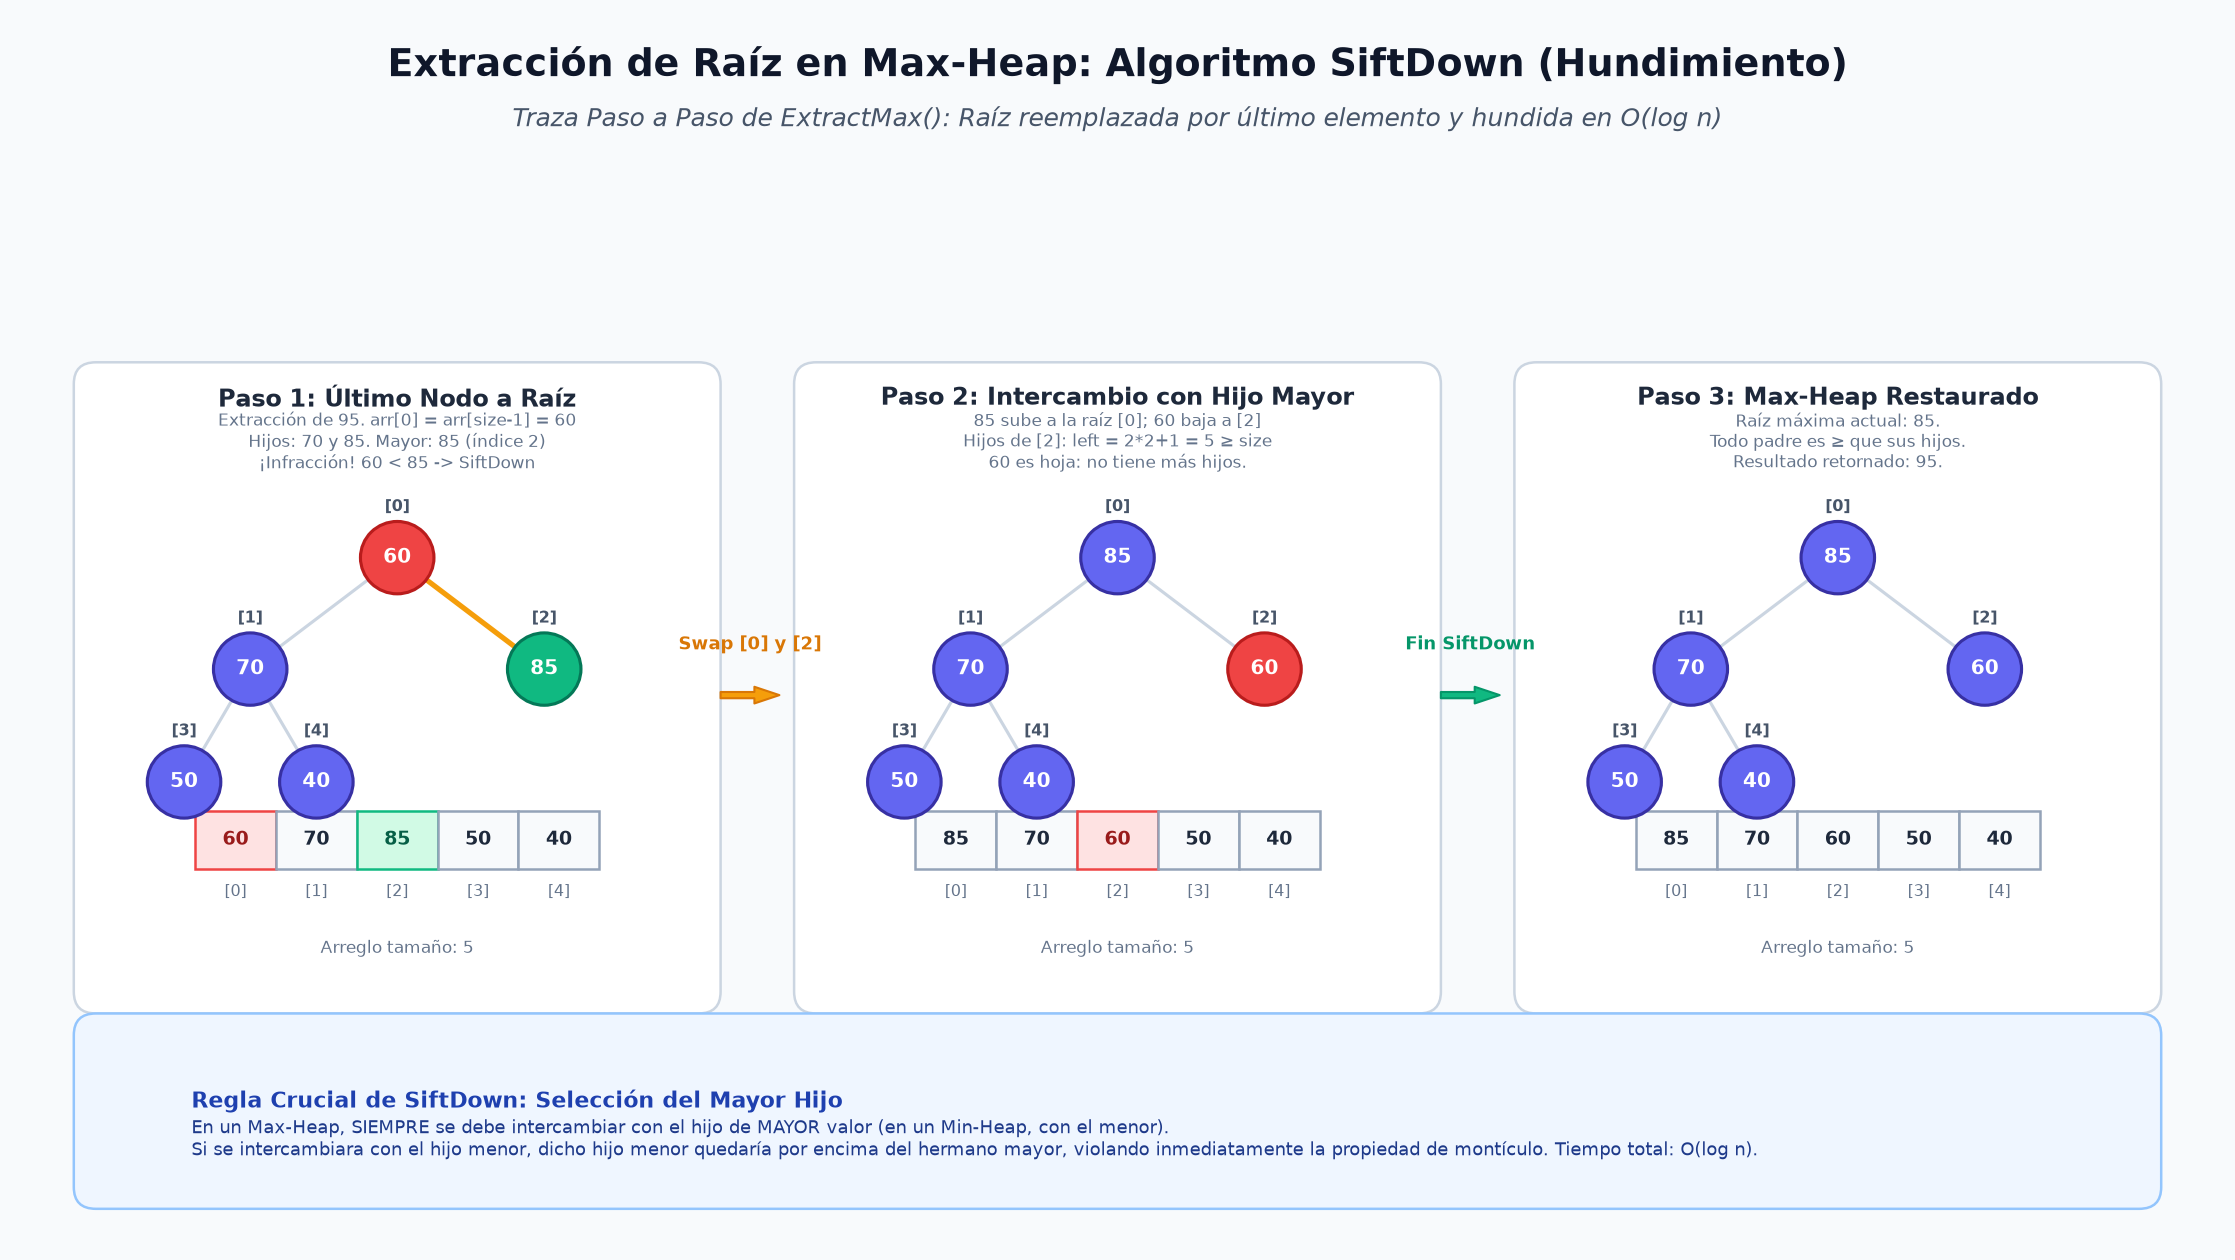
  <p><em>Figura 4: Mecánica de Extracción de Raíz y Hundimiento SiftDown paso a paso.</em></p>
</div>

### 5.3 Consulta de Extremo Inmediato (`Peek` / `GetMax` / `GetMin`) en $O(1)$
Dado que la propiedad de orden garantiza que el elemento supremo reside en la cima del árbol completo, su inspección no requiere recorridos ni rebalanceos:
$$\text{Peek}() = \text{heap}[0] \quad \longrightarrow \quad \mathbf{O(1)}$$

### 5.4 Actualización Dinámica de Prioridades (`ChangePriority`) y Eliminación Arbitraria
En algoritmos como el de Dijkstra, la prioridad (distancia estimada) de un nodo puede disminuir dinámicamente:
* Si conocemos el índice $i$ del elemento cuya prioridad cambia a $p'$:
  1. Si la nueva prioridad es mayor: llamamos a $\text{SiftUp}(i)$ en tiempo $O(\log n)$.
  2. Si la nueva prioridad es menor: llamamos a $\text{SiftDown}(i)$ en tiempo $O(\log n)$.
* **Eliminación Arbitraria (`Remove(i)`):** Podemos elevar artificialmente su prioridad a $+\infty$ para que flote a la raíz mediante $\text{SiftUp}(i)$ y luego ejecutar $\text{ExtractMax}()$ en tiempo total $O(\log n)$.


## 6. Demostraciones Prácticas en Java

---
### Demostración 1: TDA Cola de Prioridad con Arreglos Naive vs. Heap (`DemoPriorityQueueNaiveVsHeap.java`)
En este programa contrastamos empíricamente la ejecución paso a paso de las tres alternativas vistas en la teoría (Arreglo Desordenado, Arreglo Ordenado y Montículo Binario), utilizando la secuencia exacta propuesta por Alexander S. Kulikov en sus lecciones introductorias.


In [1]:
%%writefile DemoPriorityQueueNaiveVsHeap.java
import java.util.Arrays;

/**
 * Demostración 1: Comparativa del TDA Cola de Prioridad
 * Implementaciones Inocentes (Naive) vs. Montículo Binario (Heap)
 * Basado en las diapositivas de Alexander S. Kulikov y el libro de J. Streib (Cap. 10).
 */
public class DemoPriorityQueueNaiveVsHeap {

    // 1. Implementación Inocente con Arreglo Desordenado
    public static class UnsortedArrayPQ {
        private int[] data;
        private int size;

        public UnsortedArrayPQ(int capacity) {
            this.data = new int[capacity];
            this.size = 0;
        }

        // Inserción O(1): simplemente se coloca al final
        public void insert(int item) {
            if (size >= data.length) throw new IllegalStateException("Cola llena");
            data[size++] = item;
            System.out.println("  [UnsortedPQ] Insert(" + item + ") -> O(1). Arreglo: " + getArrayView());
        }

        // Extracción O(n): escaneo secuencial para buscar el máximo
        public int extractMax() {
            if (size == 0) throw new IllegalStateException("Cola vacía");
            int maxIdx = 0;
            for (int i = 1; i < size; i++) {
                if (data[i] > data[maxIdx]) {
                    maxIdx = i;
                }
            }
            int maxVal = data[maxIdx];
            // Reemplazar con el último para no dejar huecos
            data[maxIdx] = data[size - 1];
            size--;
            System.out.println("  [UnsortedPQ] ExtractMax() -> " + maxVal + " (Escaneo O(n)). Arreglo: " + getArrayView());
            return maxVal;
        }

        private String getArrayView() {
            return Arrays.toString(Arrays.copyOf(data, size));
        }
    }

    // 2. Implementación Inocente con Arreglo Ordenado (Ascendente)
    public static class SortedArrayPQ {
        private int[] data;
        private int size;

        public SortedArrayPQ(int capacity) {
            this.data = new int[capacity];
            this.size = 0;
        }

        // Inserción O(n): buscar posición y desplazar a la derecha
        public void insert(int item) {
            if (size >= data.length) throw new IllegalStateException("Cola llena");
            int i = size - 1;
            // Desplazar elementos mayores a la derecha
            while (i >= 0 && data[i] > item) {
                data[i + 1] = data[i];
                i--;
            }
            data[i + 1] = item;
            size++;
            System.out.println("  [SortedPQ] Insert(" + item + ") -> O(n) por desplazamiento. Arreglo: " + getArrayView());
        }

        // Extracción O(1): el máximo siempre está en el último índice
        public int extractMax() {
            if (size == 0) throw new IllegalStateException("Cola vacía");
            int maxVal = data[--size];
            System.out.println("  [SortedPQ] ExtractMax() -> " + maxVal + " -> O(1) directo. Arreglo: " + getArrayView());
            return maxVal;
        }

        private String getArrayView() {
            return Arrays.toString(Arrays.copyOf(data, size));
        }
    }

    // 3. Implementación con Montículo Binario (Max-Heap)
    public static class BinaryMaxHeap {
        private int[] heap;
        private int size;

        public BinaryMaxHeap(int capacity) {
            this.heap = new int[capacity];
            this.size = 0;
        }

        private int parent(int i) { return (i - 1) / 2; }
        private int leftChild(int i) { return 2 * i + 1; }
        private int rightChild(int i) { return 2 * i + 2; }

        private void swap(int i, int j) {
            int tmp = heap[i];
            heap[i] = heap[j];
            heap[j] = tmp;
        }

        // SiftUp: flotación del nuevo elemento hacia la raíz O(log n)
        private void siftUp(int i) {
            while (i > 0 && heap[i] > heap[parent(i)]) {
                int p = parent(i);
                swap(i, p);
                i = p;
            }
        }

        // SiftDown: hundimiento del elemento hacia las hojas O(log n)
        private void siftDown(int i) {
            int maxIdx = i;
            while (true) {
                int l = leftChild(i);
                int r = rightChild(i);

                if (l < size && heap[l] > heap[maxIdx]) {
                    maxIdx = l;
                }
                if (r < size && heap[r] > heap[maxIdx]) {
                    maxIdx = r;
                }

                if (i != maxIdx) {
                    swap(i, maxIdx);
                    i = maxIdx;
                } else {
                    break;
                }
            }
        }

        // Inserción en Max-Heap O(log n)
        public void insert(int item) {
            if (size >= heap.length) throw new IllegalStateException("Heap lleno");
            heap[size] = item;
            siftUp(size);
            size++;
            System.out.println("  [MaxHeap] Insert(" + item + ") -> O(log n) SiftUp. Heap: " + getArrayView());
        }

        // Extracción del Máximo O(log n)
        public int extractMax() {
            if (size == 0) throw new IllegalStateException("Heap vacío");
            int maxVal = heap[0];
            heap[0] = heap[size - 1];
            size--;
            siftDown(0);
            System.out.println("  [MaxHeap] ExtractMax() -> " + maxVal + " (O(log n) SiftDown). Heap: " + getArrayView());
            return maxVal;
        }

        public int getMax() {
            if (size == 0) throw new IllegalStateException("Heap vacío");
            return heap[0];
        }

        private String getArrayView() {
            return Arrays.toString(Arrays.copyOf(heap, size));
        }
    }

    public static void main(String[] args) {
        System.out.println("================================================================================");
        System.out.println("DEMOSTRACIÓN 1: COMPARATIVA PRÁCTICA DEL TDA COLA DE PRIORIDAD");
        System.out.println("Secuencia de Operaciones extraída de las diapositivas de Alexander S. Kulikov");
        System.out.println("================================================================================\n");

        UnsortedArrayPQ unsortedPQ = new UnsortedArrayPQ(10);
        SortedArrayPQ sortedPQ = new SortedArrayPQ(10);
        BinaryMaxHeap maxHeap = new BinaryMaxHeap(10);

        System.out.println("--- FASE 1: INSERCIÓN DE VALORES [5, 7, 1, 4] ---");
        int[] iniciales = {5, 7, 1, 4};
        for (int v : iniciales) {
            System.out.println("\n>> Insertando elemento: " + v);
            unsortedPQ.insert(v);
            sortedPQ.insert(v);
            maxHeap.insert(v);
        }

        System.out.println("\n--- FASE 2: EXTRACCIÓN DEL MÁXIMO (ExtractMax) ---");
        System.out.println("Se espera extraer 7:");
        unsortedPQ.extractMax();
        sortedPQ.extractMax();
        maxHeap.extractMax();

        System.out.println("\n--- FASE 3: INSERCIÓN INTERMEDIA DE 3 ---");
        unsortedPQ.insert(3);
        sortedPQ.insert(3);
        maxHeap.insert(3);

        System.out.println("\n--- FASE 4: EXTRACCIONES SUCESIVAS DE MÁXIMOS ---");
        System.out.println("Se esperan en orden: 5, 4, 3, 1:");
        while (maxHeap.size > 0) {
            System.out.println();
            int u = unsortedPQ.extractMax();
            int s = sortedPQ.extractMax();
            int h = maxHeap.extractMax();
            if (u != s || s != h) {
                System.err.println("¡DISCREPANCIA EN LOS RESULTADOS!");
            }
        }

        System.out.println("\n================================================================================");
        System.out.println("CONCLUSIÓN: Las 3 estructuras entregan el mismo resultado lógico.");
        System.out.println("Sin embargo, el Montículo Binario garantiza O(log n) tanto en inserción");
        System.out.println("como en extracción, evitando el cuello de botella O(n) de las estructuras inocentes.");
        System.out.println("================================================================================");
    }
}


Writing DemoPriorityQueueNaiveVsHeap.java


In [2]:
!javac -encoding UTF-8 DemoPriorityQueueNaiveVsHeap.java && java DemoPriorityQueueNaiveVsHeap


[0.014s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.014s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
DEMOSTRACIÓN 1: COMPARATIVA PRÁCTICA DEL TDA COLA DE PRIORIDAD
Secuencia de Operaciones extraída de las diapositivas de Alexander S. Kulikov

--- FASE 1: INSERCIÓN DE VALORES [5, 7, 1, 4] ---

>> Insertando elemento: 5
  [UnsortedPQ] Insert(5) -> O(1). Arreglo: [5]
  [SortedPQ] Insert(5) -> O(n) por desplazamiento. Arreglo: [5]
  [MaxHeap] 

---
### Demostración 2: Montículo Binario Genérico Industrial con Visualizador Dual (`DemoBinaryHeapVisualizer.java`)
Esta implementación presenta una clase `BinaryHeap<T>` genérica y lista para entornos de producción. Incorpora:
1. Soporte dinámico para Max-Heap o Min-Heap mediante inyección de un `Comparator<? super T>`.
2. Redimensionamiento automático de memoria (`ensureCapacity`).
3. Visualizador dual en tiempo de ejecución: imprime tanto el estado lineal contiguo del arreglo como la proyección jerárquica 2D en caracteres ASCII del árbol binario completo.


In [3]:
%%writefile DemoBinaryHeapVisualizer.java
import java.util.Arrays;
import java.util.Comparator;
import java.util.NoSuchElementException;

/**
 * Demostración 2: Montículo Binario Genérico (BinaryHeap<T>) con Visualizador Dual
 * Permite configurar modo Min-Heap o Max-Heap mediante Comparator<T>.
 * Incluye visualización dual: Arreglo Contiguo y Árbol Jerárquico en ASCII.
 */
public class DemoBinaryHeapVisualizer {

    public static class BinaryHeap<T> {
        private Object[] elements;
        private int size;
        private final Comparator<? super T> comparator;
        private static final int DEFAULT_CAPACITY = 10;

        @SuppressWarnings("unchecked")
        public BinaryHeap(Comparator<? super T> comparator) {
            this.elements = new Object[DEFAULT_CAPACITY];
            this.size = 0;
            this.comparator = (comparator != null) ? comparator : (a, b) -> ((Comparable<T>) a).compareTo(b);
        }

        public BinaryHeap() {
            this(null);
        }

        public int size() { return size; }
        public boolean isEmpty() { return size == 0; }

        private int parent(int i) { return (i - 1) / 2; }
        private int leftChild(int i) { return 2 * i + 1; }
        private int rightChild(int i) { return 2 * i + 2; }

        @SuppressWarnings("unchecked")
        private int compare(int i, int j) {
            return comparator.compare((T) elements[i], (T) elements[j]);
        }

        private void swap(int i, int j) {
            Object temp = elements[i];
            elements[i] = elements[j];
            elements[j] = temp;
        }

        private void ensureCapacity() {
            if (size >= elements.length) {
                elements = Arrays.copyOf(elements, elements.length * 2);
            }
        }

        // SiftUp: sube el elemento hasta restaurar la propiedad del montículo
        private void siftUp(int i) {
            while (i > 0 && compare(i, parent(i)) > 0) {
                int p = parent(i);
                swap(i, p);
                i = p;
            }
        }

        // SiftDown: hunde el elemento intercambiando con el hijo prioritario
        private void siftDown(int i) {
            int targetIdx = i;
            while (true) {
                int l = leftChild(i);
                int r = rightChild(i);

                if (l < size && compare(l, targetIdx) > 0) {
                    targetIdx = l;
                }
                if (r < size && compare(r, targetIdx) > 0) {
                    targetIdx = r;
                }

                if (i != targetIdx) {
                    swap(i, targetIdx);
                    i = targetIdx;
                } else {
                    break;
                }
            }
        }

        public void insert(T item) {
            if (item == null) throw new IllegalArgumentException("No se permiten elementos nulos");
            ensureCapacity();
            elements[size] = item;
            siftUp(size);
            size++;
        }

        @SuppressWarnings("unchecked")
        public T extract() {
            if (isEmpty()) throw new NoSuchElementException("El montículo está vacío");
            T result = (T) elements[0];
            elements[0] = elements[size - 1];
            elements[size - 1] = null; // Evitar memory leaks en la JVM
            size--;
            if (size > 0) {
                siftDown(0);
            }
            return result;
        }

        @SuppressWarnings("unchecked")
        public T peek() {
            if (isEmpty()) throw new NoSuchElementException("El montículo está vacío");
            return (T) elements[0];
        }

        // Visualizador 1: Arreglo Contiguo con Índices
        public void imprimirArreglo() {
            System.out.print("  [ARREGLO] (size=" + size + "): ");
            for (int i = 0; i < size; i++) {
                System.out.print("[" + i + ":" + elements[i] + "] ");
            }
            System.out.println();
        }

        // Visualizador 2: Jerarquía de Árbol en Consola
        public void imprimirArbol() {
            System.out.println("  [ÁRBOL CONCEPTUAL]:");
            if (isEmpty()) {
                System.out.println("    (Árbol vacío)");
                return;
            }
            imprimirArbolRecursivo(0, "", true);
        }

        private void imprimirArbolRecursivo(int i, String prefix, boolean isTail) {
            if (i >= size) return;
            System.out.println("    " + prefix + (isTail ? "└── " : "├── ") + elements[i] + " [idx:" + i + "]");
            int l = leftChild(i);
            int r = rightChild(i);
            boolean hasLeft = l < size;
            boolean hasRight = r < size;

            if (hasLeft && hasRight) {
                imprimirArbolRecursivo(l, prefix + (isTail ? "    " : "│   "), false);
                imprimirArbolRecursivo(r, prefix + (isTail ? "    " : "│   "), true);
            } else if (hasLeft) {
                imprimirArbolRecursivo(l, prefix + (isTail ? "    " : "│   "), true);
            }
        }
    }

    public static void main(String[] args) {
        System.out.println("================================================================================");
        System.out.println("DEMOSTRACIÓN 2: MONTÍCULO BINARIO INDUSTRIAL (MAX-HEAP Y MIN-HEAP)");
        System.out.println("Visualización en tiempo de ejecución: Arreglo Físico vs. Árbol Conceptual");
        System.out.println("================================================================================\n");

        // Creamos un Max-Heap de enteros
        System.out.println("=== CONFIGURACIÓN 1: MAX-HEAP DE PRIORIDADES DE TRABAJO ===");
        BinaryHeap<Integer> maxHeap = new BinaryHeap<>(Comparator.naturalOrder());

        int[] datos = {50, 30, 80, 20, 90, 70, 60};
        System.out.println("Insertando valores sucesivamente: " + Arrays.toString(datos) + "\n");

        for (int v : datos) {
            System.out.println(">>> INSERTANDO: " + v);
            maxHeap.insert(v);
            maxHeap.imprimirArreglo();
            maxHeap.imprimirArbol();
            System.out.println();
        }

        System.out.println("================================================================================");
        System.out.println("=== CONFIGURACIÓN 2: EXTRACCIONES DEL ELEMENTO CON MÁXIMA PRIORIDAD ===");
        System.out.println("================================================================================");

        while (!maxHeap.isEmpty()) {
            System.out.println("Extremo peek(): " + maxHeap.peek());
            int extraido = maxHeap.extract();
            System.out.println(">>> EXTRAÍDO: " + extraido);
            maxHeap.imprimirArreglo();
            maxHeap.imprimirArbol();
            System.out.println();
        }

        System.out.println("=== CONFIGURACIÓN 3: MIN-HEAP DE TIEMPOS DE RESPUESTA (ms) ===");
        // Min-heap usando comparator inverso
        BinaryHeap<Double> minHeap = new BinaryHeap<>(Comparator.reverseOrder());
        double[] tiempos = {12.4, 3.1, 45.0, 1.8, 8.5};
        System.out.println("Insertando tiempos de respuesta: " + Arrays.toString(tiempos));
        for (double t : tiempos) minHeap.insert(t);

        minHeap.imprimirArreglo();
        minHeap.imprimirArbol();
        System.out.println("Menor tiempo de respuesta (raíz Min-Heap): " + minHeap.peek() + " ms");
    }
}


Writing DemoBinaryHeapVisualizer.java


In [4]:
!javac -encoding UTF-8 DemoBinaryHeapVisualizer.java && java DemoBinaryHeapVisualizer


[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
DEMOSTRACIÓN 2: MONTÍCULO BINARIO INDUSTRIAL (MAX-HEAP Y MIN-HEAP)
Visualización en tiempo de ejecución: Arreglo Físico vs. Árbol Conceptual

=== CONFIGURACIÓN 1: MAX-HEAP DE PRIORIDADES DE TRABAJO ===
Insertando valores sucesivamente: [50, 30, 80, 20, 90, 70, 60]

>>> INSERTANDO: 50
  [ARREGLO] (size=1): [0:50] 
  [ÁRBOL CONCEPTUAL]:
    └

## 7. Comparativa Estructural y de Ingeniería de Software (Árbol AVL vs. Montículo Binario)

Es común que los estudiantes se pregunten: *¿Si el Árbol AVL garantiza operaciones en $O(\log n)$, por qué necesitamos inventar el Montículo Binario?*

<div align="center">
  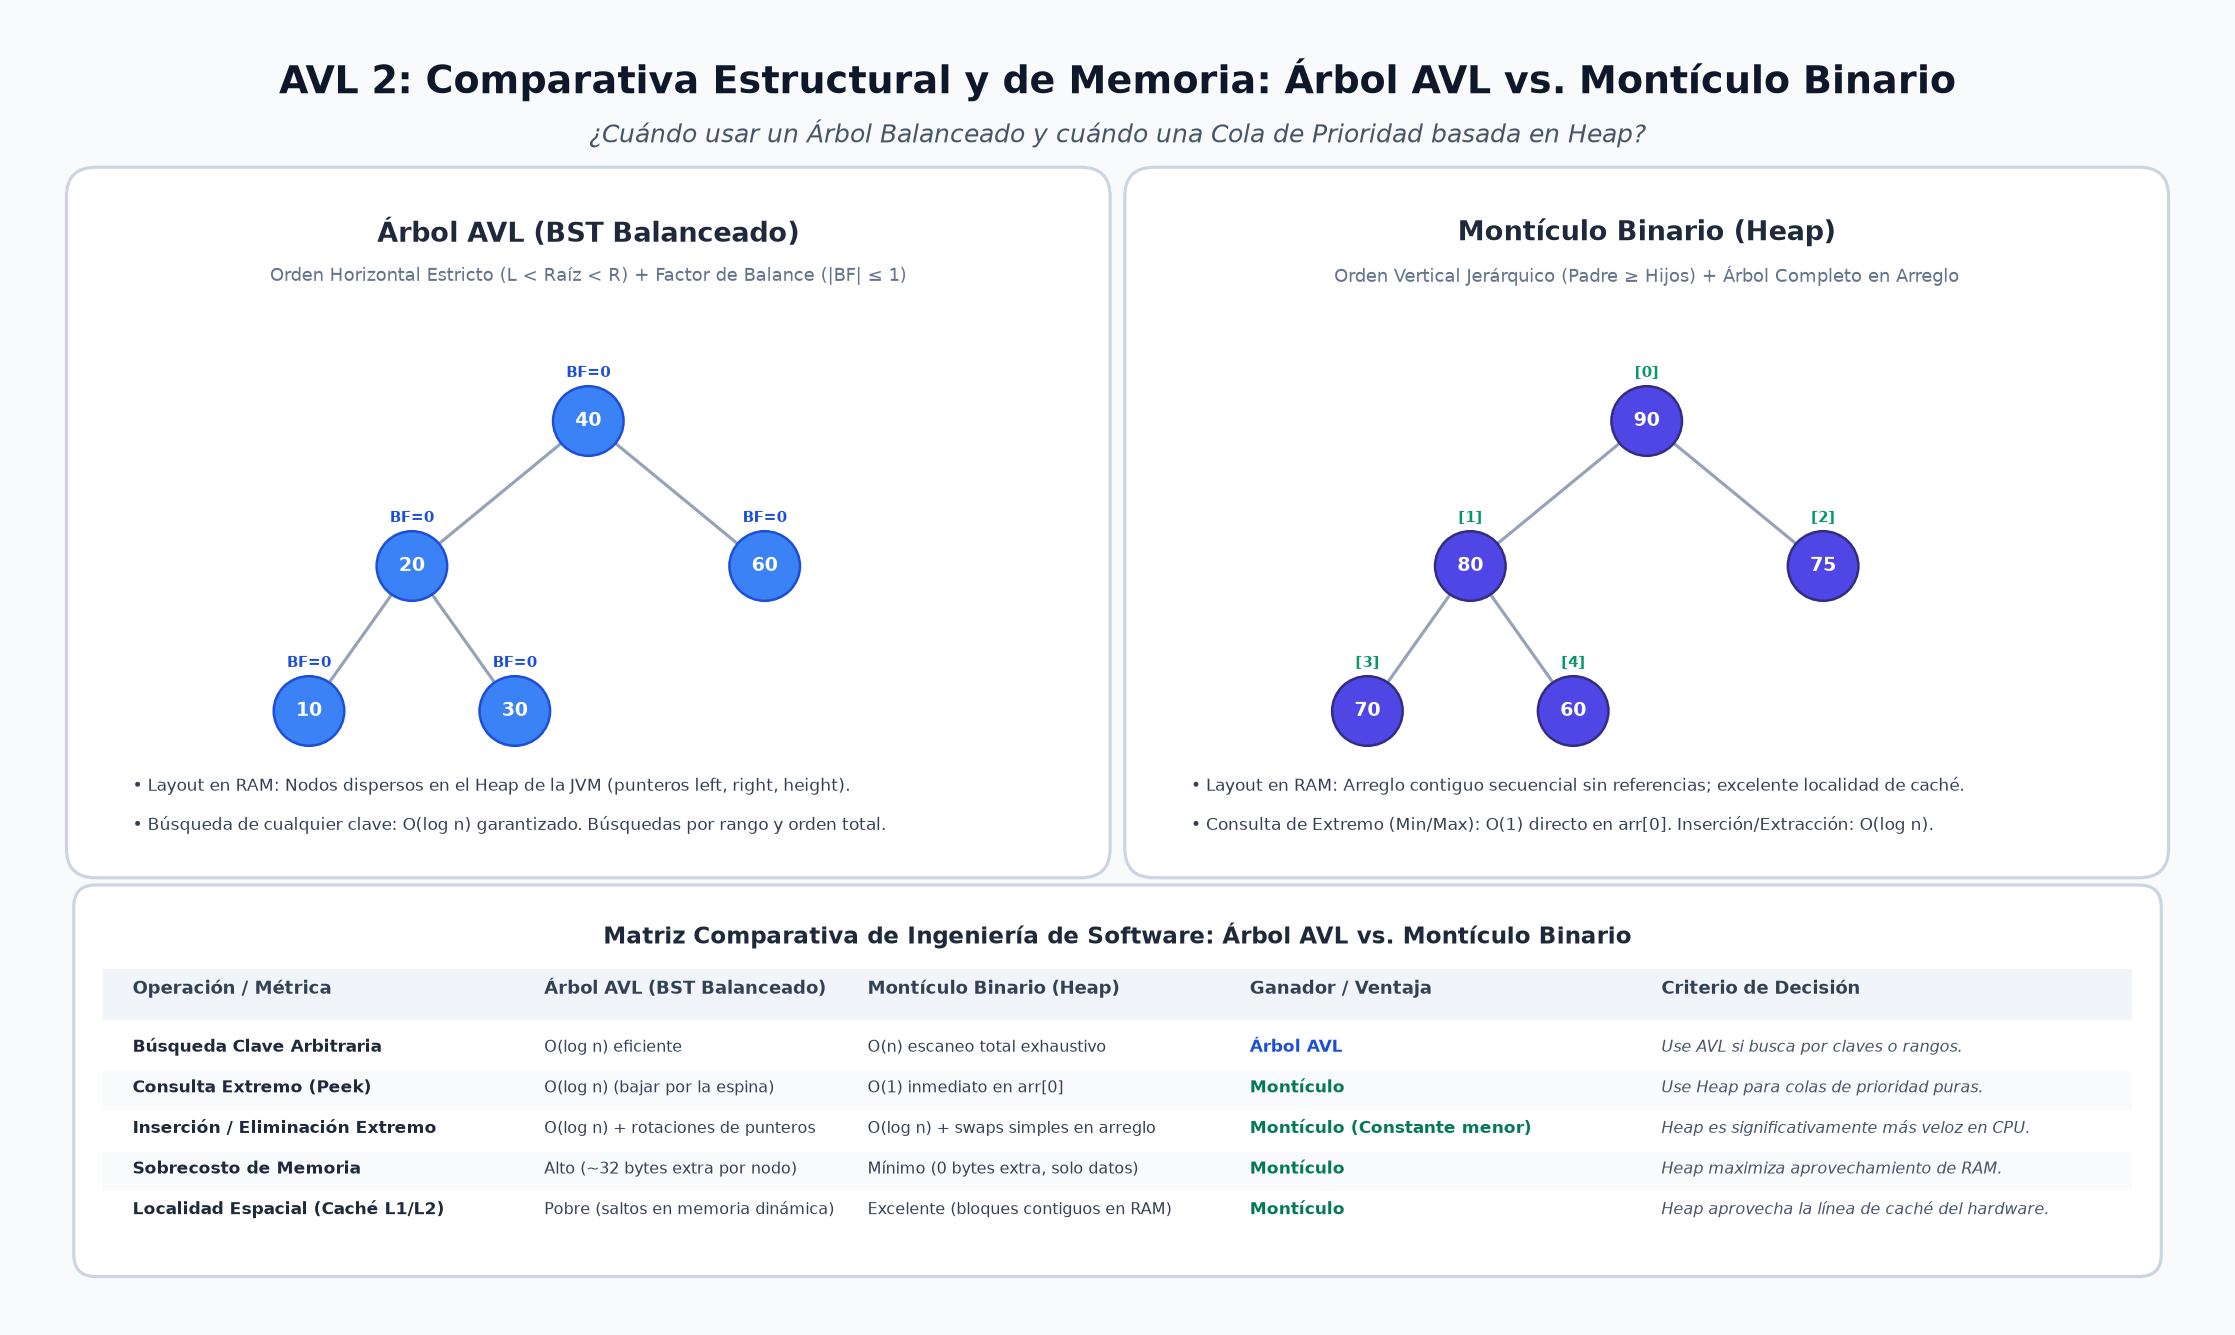
  <p><em>Figura 5: Comparativa Estructural, Memoria y Matriz de Rendimiento entre Árbol AVL y Montículo Binario.</em></p>
</div>

### 7.1 ¿Puede un Árbol AVL actuar como Cola de Prioridad? Análisis de Sobrecosto
Teóricamente, un Árbol AVL puede utilizarse para implementar una cola de prioridad:
* **Consulta de Extremo (`PeekMax`):** En un AVL, el elemento máximo no está en la raíz, sino en el nodo más a la derecha. Encontrar el extremo requiere descender por la espina derecha del árbol, tomando tiempo **$O(\log n)$** (frente al **$O(1)$** inmediato del Heap).
* **Extracción de Extremo (`ExtractMax`):** Se elimina el nodo más a la derecha y se ejecutan rebalanceos hacia arriba con rotaciones simples o dobles. Toma tiempo $O(\log n)$, pero con un factor de constante oculta muy alto debido a la inspección de factores de balance ($BF$) y actualización de alturas.

### 7.2 Disparidad de Memoria y Huella de Objetos en la JVM
Para almacenar $100{,}000$ elementos numéricos:
* **Árbol AVL:** Genera $100{,}000$ objetos individuales en el *heap* de la JVM. Cada nodo incluye cabecera de objeto (16 bytes), valor (4 u 8 bytes), puntero `left` (8 bytes), puntero `right` (8 bytes) y campo `height` (4 bytes), totalizando aproximadamente **40 a 48 bytes por elemento**. Además, estos nodos quedan dispersos de forma fragmentada en la memoria RAM, castigando drásticamente la tasa de aciertos de la caché del procesador.
* **Montículo Binario:** Aloja los $100{,}000$ elementos en **un único arreglo contiguo de primitivos** `int[]`. El sobrecosto por elemento es de **0 bytes**. La memoria física es continua y los accesos aprovechan al 100% las líneas de caché L1 y L2 del hardware.

### 7.3 Matriz de Decisión Arquitectónica: Cuándo Utilizar AVL y Cuándo Utilizar Heap

| Requerimiento del Sistema / Problema | Estructura Óptima Recomendada | Justificación de Ingeniería |
| :--- | :---: | :--- |
| **Cola de Prioridad Pura / Despacho de Trabajos** | **Montículo Binario (Heap)** | `Peek` en $O(1)$, menor consumo de RAM, 3x a 5x más rápido en CPU. |
| **Búsqueda por Clave Exacta (`Search(k)`)** | **Árbol AVL** | AVL busca en $O(\log n)$; el Heap degenera en escaneo lineal $O(n)$. |
| **Consultas por Rango ($[K_{min}, K_{max}]$)** | **Árbol AVL** | Su orden horizontal estricto permite barridos in-order ordenados en tiempo óptimo. |
| **Predecesor y Sucesor Inmediato** | **Árbol AVL** | El orden horizontal de los BST permite hallar vecinos ordenados en $O(\log n)$. |
| **Algoritmo de Dijkstra / Prim / Huffman** | **Montículo Binario (Heap)** | Solo se extrae el mínimo continuamente; no se requieren búsquedas arbitrarias. |


---
### Demostración 3: AVL vs. Binary Heap
El siguiente programa pone a prueba ambas estructuras bajo un escenario de estrés real con **50,000 elementos aleatorios**, midiendo con precisión de nanosegundos el tiempo real de inserción y vaciado masivo en la máquina virtual.


In [9]:
%%writefile DemoAVLVsHeapOnlineGDB.java
import java.util.Random;

/**
 * Demostración 3: AVL vs. Montículo Binario
 * Analiza empírica y estructuralmente por qué un Montículo Binario supera drásticamente
 * a un Árbol AVL como Cola de Prioridad, y en qué escenarios el AVL sigue siendo insustituible.
 */
public class DemoAVLVsHeapOnlineGDB {

    // ---------------------------------------------------------
    // 1. Cola de Prioridad basada en Árbol AVL
    // ---------------------------------------------------------
    public static class AVLTreePQ {
        private static class Node {
            int key;
            int height;
            Node left, right;
            Node(int key) {
                this.key = key;
                this.height = 1;
            }
        }

        private Node root;
        private int size;

        private int height(Node n) { return n == null ? 0 : n.height; }
        private int balanceFactor(Node n) { return n == null ? 0 : height(n.left) - height(n.right); }
        private void updateHeight(Node n) { n.height = 1 + Math.max(height(n.left), height(n.right)); }

        private Node rotateRight(Node y) {
            Node x = y.left;
            Node T2 = x.right;
            x.right = y;
            y.left = T2;
            updateHeight(y);
            updateHeight(x);
            return x;
        }

        private Node rotateLeft(Node x) {
            Node y = x.right;
            Node T2 = y.left;
            y.left = x;
            x.right = T2;
            updateHeight(x);
            updateHeight(y);
            return y;
        }

        private Node balance(Node n) {
            updateHeight(n);
            int bf = balanceFactor(n);
            if (bf > 1) {
                if (balanceFactor(n.left) < 0) n.left = rotateLeft(n.left);
                return rotateRight(n);
            }
            if (bf < -1) {
                if (balanceFactor(n.right) > 0) n.right = rotateRight(n.right);
                return rotateLeft(n);
            }
            return n;
        }

        public void insert(int key) {
            root = insertRec(root, key);
            size++;
        }

        private Node insertRec(Node n, int key) {
            if (n == null) return new Node(key);
            if (key <= n.key) n.left = insertRec(n.left, key);
            else n.right = insertRec(n.right, key);
            return balance(n);
        }

        // En un AVL, el máximo está en el extremo derecho O(log n)
        public int peekMax() {
            if (root == null) throw new IllegalStateException("Cola vacía");
            Node curr = root;
            while (curr.right != null) curr = curr.right;
            return curr.key;
        }

        public int extractMax() {
            if (root == null) throw new IllegalStateException("Cola vacía");
            int maxVal = peekMax();
            root = deleteMaxRec(root);
            size--;
            return maxVal;
        }

        private Node deleteMaxRec(Node n) {
            if (n.right == null) return n.left;
            n.right = deleteMaxRec(n.right);
            return balance(n);
        }

        public int size() { return size; }
    }

    // ---------------------------------------------------------
    // 2. Cola de Prioridad basada en Montículo Binario (Max-Heap)
    // ---------------------------------------------------------
    public static class BinaryMaxHeapPQ {
        private int[] data;
        private int size;

        public BinaryMaxHeapPQ(int capacity) {
            data = new int[capacity];
            size = 0;
        }

        private void swap(int i, int j) {
            int t = data[i]; data[i] = data[j]; data[j] = t;
        }

        public void insert(int val) {
            if (size == data.length) {
                int[] nuevo = new int[data.length * 2];
                System.arraycopy(data, 0, nuevo, 0, data.length);
                data = nuevo;
            }
            data[size] = val;
            int i = size;
            size++;
            // SiftUp
            while (i > 0) {
                int p = (i - 1) / 2;
                if (data[i] > data[p]) {
                    swap(i, p);
                    i = p;
                } else break;
            }
        }

        public int peekMax() {
            if (size == 0) throw new IllegalStateException("Cola vacía");
            return data[0]; // O(1) directo
        }

        public int extractMax() {
            if (size == 0) throw new IllegalStateException("Cola vacía");
            int res = data[0];
            data[0] = data[size - 1];
            size--;
            // SiftDown
            int i = 0;
            while (true) {
                int l = 2 * i + 1;
                int r = 2 * i + 2;
                int largest = i;
                if (l < size && data[l] > data[largest]) largest = l;
                if (r < size && data[r] > data[largest]) largest = r;
                if (largest != i) {
                    swap(i, largest);
                    i = largest;
                } else break;
            }
            return res;
        }

        public int size() { return size; }
    }

    public static void main(String[] args) {
        System.out.println("================================================================================");
        System.out.println("DEMOSTRACIÓN 3: AVL VS. BINARY HEAP");
        System.out.println("================================================================================\n");

        final int N = 50_000;
        Random rand = new Random(42);
        int[] dataset = new int[N];
        for (int i = 0; i < N; i++) dataset[i] = rand.nextInt(1_000_000);

        System.out.println("Conjunto de prueba generado: " + N + " números enteros pseudoaleatorios.");
        System.out.println("Ejecutando pruebas de inserción y extracción masiva...\n");

        // --- PRUEBA 1: MONTÍCULO BINARIO (HEAP) ---
        BinaryMaxHeapPQ heap = new BinaryMaxHeapPQ(100);
        long t0Heap = System.nanoTime();
        for (int v : dataset) heap.insert(v);
        long t1Heap = System.nanoTime();

        long t2Heap = System.nanoTime();
        while (heap.size() > 0) heap.extractMax();
        long t3Heap = System.nanoTime();

        double heapInsertMs = (t1Heap - t0Heap) / 1e6;
        double heapExtractMs = (t3Heap - t2Heap) / 1e6;
        double heapTotalMs = heapInsertMs + heapExtractMs;

        // --- PRUEBA 2: ÁRBOL AVL ---
        AVLTreePQ avl = new AVLTreePQ();
        long t0Avl = System.nanoTime();
        for (int v : dataset) avl.insert(v);
        long t1Avl = System.nanoTime();

        long t2Avl = System.nanoTime();
        while (avl.size() > 0) avl.extractMax();
        long t3Avl = System.nanoTime();

        double avlInsertMs = (t1Avl - t0Avl) / 1e6;
        double avlExtractMs = (t3Avl - t2Avl) / 1e6;
        double avlTotalMs = avlInsertMs + avlExtractMs;

        System.out.println("--------------------------------------------------------------------------------");
        System.out.printf("%-30s | %-18s | %-18s%n", "Operación (N = " + N + ")", "Montículo Binario", "Árbol AVL");
        System.out.println("--------------------------------------------------------------------------------");
        System.out.printf("%-30s | %14.2f ms | %14.2f ms%n", "Inserción masiva (" + N + ")", heapInsertMs, avlInsertMs);
        System.out.printf("%-30s | %14.2f ms | %14.2f ms%n", "Extracción masiva (" + N + ")", heapExtractMs, avlExtractMs);
        System.out.printf("%-30s | %14.2f ms | %14.2f ms%n", "TIEMPO TOTAL", heapTotalMs, avlTotalMs);
        System.out.println("--------------------------------------------------------------------------------");
        double factorVelocidad = avlTotalMs / heapTotalMs;
        System.out.printf("FACTOR DE ACELERACIÓN: El Montículo Binario fue %.2fx más rápido.%n", factorVelocidad);
        System.out.println("================================================================================");
        System.out.println("ANÁLISIS PEDAGÓGICO DE LA DISPARIDAD:");
        System.out.println("1. ASIGNACIÓN DINÁMICA: AVL crea " + N + " instancias de objetos (Node) con 32+ bytes c/u.");
        System.out.println("   El Heap solo redimensiona un arreglo contiguo (0 objetos por inserción).");
        System.out.println("2. LOCALIDAD DE CACHÉ: En el Heap, los parientes están a saltos aritméticos en memoria");
        System.out.println("   contigua. En el AVL, cada puntero 'left' o 'right' provoca un cache miss en el CPU.");
        System.out.println("3. CONDICIÓN DE ROTACIÓN: AVL reevalúa alturas y balance en cada nivel de retorno.");
        System.out.println("   El Heap solo realiza swaps elementales en un bucle simple.");
        System.out.println("================================================================================");
    }
}


Overwriting DemoAVLVsHeapOnlineGDB.java


In [10]:
!javac -encoding UTF-8 DemoAVLVsHeapOnlineGDB.java && java DemoAVLVsHeapOnlineGDB


[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
DEMOSTRACIÓN 3: AVL VS. BINARY HEAP

Conjunto de prueba generado: 50000 números enteros pseudoaleatorios.
Ejecutando pruebas de inserción y extracción masiva...

--------------------------------------------------------------------------------
Operación (N = 50000)          | Montículo Binario  | Árbol AVL         
--------------------------

## 8. Buenas Prácticas y Errores Frecuentes (*Pitfalls*) en la Implementación de Heaps

Al diseñar e implementar colas de prioridad y montículos en Java y C++, es indispensable evitar los siguientes errores arquitectónicos comunes:

1. **Error de Desfase de Índices (Base 0 vs. Base 1):**
   * El error más habitual consiste en aplicar las fórmulas clásicas de los libros de texto (`2*i` y `2*i + 1`) en arreglos indexados desde 0.
   * Si la raíz está en `0`, calcular `2*0` produce `0` (un ciclo infinito donde la raíz es su propio hijo izquierdo). **En Java siempre se debe usar:**
     $$\text{left} = 2i + 1, \quad \text{right} = 2i + 2, \quad \text{parent} = (i - 1) / 2$$

2. **Intercambio Erróneo con el Hijo Menor en Max-Heap durante SiftDown:**
   * En `siftDown`, si un nodo tiene dos hijos y viola la propiedad de montículo, **siempre debe intercambiarse con el hijo MAYOR** (en Max-Heap) o con el **MENOR** (en Min-Heap).
   * Si se intercambiara con el hijo menor, dicho hijo menor pasaría a ocupar el lugar del padre, quedando por encima del hermano mayor que no se movió, violando inmediatamente el orden del montículo en ese subárbol.

3. **Verificación Estricta de Límites de Tamaño (`OutOfBounds`):**
   * Antes de inspeccionar `heap[leftChild]` o `heap[rightChild]`, es obligatorio comprobar que los índices calculados sean estrictamente menores que `size` (`leftChild < size`).
   * Un nodo puede tener únicamente hijo izquierdo (en el último nivel de un árbol completo). Si se intenta consultar el hijo derecho sin verificar `rightChild < size`, se generará una excepción `ArrayIndexOutOfBoundsException`.

4. **Fuga de Memoria (*Memory Leaks*) en Clases Genéricas de Java:**
   * Al decrementar `size` en `extract()`, si el arreglo almacena referencias a objetos (`Object[]`), la última celda debe asignarse explícitamente a `null` (`elements[size - 1] = null`). De lo contrario, la referencia continuará retenida en el arreglo subyacente, impidiendo que el recolector de basura (*Garbage Collector*) libere la memoria.

5. **No Intentar Búsqueda Binaria en un Heap:**
   * Recordar que un Heap no tiene orden horizontal. Si su aplicación requiere comprobar frecuentemente si un elemento existe mediante `contains(x)` o consultar rangos, un Heap obligará a un costoso barrido $O(n)$. En ese caso, la estructura correcta es un Árbol AVL o un `TreeSet`.


## 9. Ejercicios Prácticos

Los siguientes 5 ejercicios han sido diseñados para afianzar cada componente crítico de los montículos binarios y las colas de prioridad. Cada ejercicio incluye una suite de pruebas unitarias automatizadas con reporte de puntuación (escala 0 a 100).

---
### Ejercicio 1: Implementación de `SiftUp` en un Max-Heap (`Ejercicio1SiftUpMaxHeap.java`)
**Objetivo:** Completar el método `siftUp(int i)` en un Max-Heap que utiliza indexación base 0. El método debe hacer flotar el elemento en la posición `i` intercambiándolo con su padre mientras su valor sea superior y no haya alcanzado la raíz (`i > 0`).


In [ ]:
%%writefile Ejercicio1SiftUpMaxHeap.java
import java.util.Arrays;

public class Ejercicio1SiftUpMaxHeap {

    public static class MaxHeap {
        public int[] heap;
        public int size;

        public MaxHeap(int capacity) {
            this.heap = new int[capacity];
            this.size = 0;
        }

        public int parent(int i) { return (i - 1) / 2; }

        public void swap(int i, int j) {
            int tmp = heap[i];
            heap[i] = heap[j];
            heap[j] = tmp;
        }

        // =====================================================================
        // TODO: Implementar el método siftUp para un Max-Heap en base 0
        // Debe flotar el elemento en el índice i mientras sea mayor que su padre
        // y no haya alcanzado la raíz (i > 0).
        // =====================================================================
        public void siftUp(int i) {
            while (i > 0 && heap[i] > heap[parent(i)]) {
                int p = parent(i);
                swap(i, p);
                i = p;
            }
        }

        public void insert(int val) {
            if (size >= heap.length) throw new IllegalStateException("Heap lleno");
            heap[size] = val;
            siftUp(size);
            size++;
        }
    }

    public static void main(String[] args) {
        System.out.println("=================================================");
        System.out.println("EJERCICIO 1: IMPLEMENTACIÓN DE SIFTUP EN MAX-HEAP");
        System.out.println("=================================================");

        int score = 0;
        int totalTests = 5;

        // Test 1: Inserción elemento único
        try {
            MaxHeap h = new MaxHeap(10);
            h.insert(42);
            if (h.size == 1 && h.heap[0] == 42) {
                System.out.println("✓ Test 1 Superado: Inserción en heap vacío correcta.");
                score += 20;
            } else {
                System.out.println("✗ Test 1 Falló: Raíz incorrecta.");
            }
        } catch (Exception e) { System.out.println("✗ Test 1 Excepción: " + e.getMessage()); }

        // Test 2: Inserción de elementos menores (no deben flotar)
        try {
            MaxHeap h = new MaxHeap(10);
            h.insert(50);
            h.insert(30);
            h.insert(20);
            if (h.heap[0] == 50 && h.heap[1] == 30 && h.heap[2] == 20) {
                System.out.println("✓ Test 2 Superado: Elementos menores se mantienen en sus posiciones.");
                score += 20;
            } else {
                System.out.println("✗ Test 2 Falló: " + Arrays.toString(Arrays.copyOf(h.heap, h.size)));
            }
        } catch (Exception e) { System.out.println("✗ Test 2 Excepción: " + e.getMessage()); }

        // Test 3: Inserción de nuevo máximo absoluto (debe flotar hasta la raíz)
        try {
            MaxHeap h = new MaxHeap(10);
            h.insert(10);
            h.insert(20);
            h.insert(30);
            h.insert(100); // Debe terminar en heap[0]
            if (h.heap[0] == 100) {
                System.out.println("✓ Test 3 Superado: Nuevo máximo absoluto flotó hasta la raíz [0].");
                score += 20;
            } else {
                System.out.println("✗ Test 3 Falló: Raíz no es 100 sino " + h.heap[0]);
            }
        } catch (Exception e) { System.out.println("✗ Test 3 Excepción: " + e.getMessage()); }

        // Test 4: Traza de Kulikov [5, 7, 1, 4] -> [7, 5, 1, 4]
        try {
            MaxHeap h = new MaxHeap(10);
            h.insert(5);
            h.insert(7);
            h.insert(1);
            h.insert(4);
            int[] esperado = {7, 5, 1, 4};
            int[] actual = Arrays.copyOf(h.heap, 4);
            if (Arrays.equals(actual, esperado)) {
                System.out.println("✓ Test 4 Superado: Secuencia de Kulikov genera exactamente [7, 5, 1, 4].");
                score += 20;
            } else {
                System.out.println("✗ Test 4 Falló: Esperado " + Arrays.toString(esperado) + ", obtenido " + Arrays.toString(actual));
            }
        } catch (Exception e) { System.out.println("✗ Test 4 Excepción: " + e.getMessage()); }

        // Test 5: Inserción de valores duplicados
        try {
            MaxHeap h = new MaxHeap(10);
            h.insert(40);
            h.insert(40);
            h.insert(40);
            h.insert(40);
            if (h.size == 4 && h.heap[0] == 40 && h.heap[1] == 40) {
                System.out.println("✓ Test 5 Superado: Duplicados preservan estructura de árbol completo.");
                score += 20;
            } else {
                System.out.println("✗ Test 5 Falló con duplicados.");
            }
        } catch (Exception e) { System.out.println("✗ Test 5 Excepción: " + e.getMessage()); }

        System.out.println("\n-------------------------------------------------");
        System.out.println("PUNTUACIÓN FINAL EJERCICIO 1: " + score + " / 100");
        System.out.println("-------------------------------------------------");
    }
}


In [ ]:
!javac -encoding UTF-8 Ejercicio1SiftUpMaxHeap.java && java Ejercicio1SiftUpMaxHeap


---
### Ejercicio 2: Implementación de `SiftDown` en un Min-Heap (`Ejercicio2SiftDownMinHeap.java`)
**Objetivo:** Implementar el método `siftDown(int i)` en un Min-Heap. El algoritmo debe comparar el nodo con sus hijos izquierdo y derecho, seleccionar el menor de ellos y descender mediante intercambios hasta que la propiedad de Min-Heap se cumpla en su totalidad.


In [ ]:
%%writefile Ejercicio2SiftDownMinHeap.java
import java.util.Arrays;
import java.util.NoSuchElementException;

public class Ejercicio2SiftDownMinHeap {

    public static class MinHeap {
        public int[] heap;
        public int size;

        public MinHeap(int capacity) {
            this.heap = new int[capacity];
            this.size = 0;
        }

        public int leftChild(int i) { return 2 * i + 1; }
        public int rightChild(int i) { return 2 * i + 2; }

        public void swap(int i, int j) {
            int tmp = heap[i];
            heap[i] = heap[j];
            heap[j] = tmp;
        }

        // =====================================================================
        // TODO: Implementar el método siftDown para un Min-Heap en base 0
        // Debe hundir el elemento en el índice i comparándolo con sus hijos
        // e intercambiándolo con el hijo MENOR si alguno es menor que heap[i].
        // Continuar hasta que ningún hijo sea menor o sea una hoja.
        // =====================================================================
        public void siftDown(int i) {
            int minIdx = i;
            while (true) {
                int l = leftChild(i);
                int r = rightChild(i);

                if (l < size && heap[l] < heap[minIdx]) {
                    minIdx = l;
                }
                if (r < size && heap[r] < heap[minIdx]) {
                    minIdx = r;
                }

                if (minIdx != i) {
                    swap(i, minIdx);
                    i = minIdx;
                } else {
                    break;
                }
            }
        }

        public void insert(int val) {
            if (size >= heap.length) throw new IllegalStateException("Heap lleno");
            heap[size] = val;
            // SiftUp básico para armar el heap
            int cur = size;
            while (cur > 0 && heap[cur] < heap[(cur - 1) / 2]) {
                swap(cur, (cur - 1) / 2);
                cur = (cur - 1) / 2;
            }
            size++;
        }

        public int extractMin() {
            if (size == 0) throw new NoSuchElementException("Heap vacío");
            int minVal = heap[0];
            heap[0] = heap[size - 1];
            size--;
            if (size > 0) {
                siftDown(0);
            }
            return minVal;
        }
    }

    public static void main(String[] args) {
        System.out.println("===================================================");
        System.out.println("EJERCICIO 2: IMPLEMENTACIÓN DE SIFTDOWN EN MIN-HEAP");
        System.out.println("===================================================");

        int score = 0;

        // Test 1: Extracción en heap de un solo elemento
        try {
            MinHeap h = new MinHeap(10);
            h.insert(88);
            int min = h.extractMin();
            if (min == 88 && h.size == 0) {
                System.out.println("✓ Test 1 Superado: Extracción de elemento único correcta.");
                score += 20;
            } else {
                System.out.println("✗ Test 1 Falló.");
            }
        } catch (Exception e) { System.out.println("✗ Test 1 Excepción: " + e.getMessage()); }

        // Test 2: Hundimiento hacia hijo izquierdo (cuando solo tiene hijo izq o izq es menor)
        try {
            MinHeap h = new MinHeap(10);
            // Insertar de modo que al extraer, la raíz se hunda por la izquierda
            h.insert(10);
            h.insert(20);
            h.insert(50);
            h.insert(30);
            // Extraer 10 -> 30 pasa a raíz y debe intercambiar con 20 (hijo izquierdo)
            int min = h.extractMin();
            if (min == 10 && h.heap[0] == 20) {
                System.out.println("✓ Test 2 Superado: Hundimiento correcto hacia el hijo izquierdo menor.");
                score += 20;
            } else {
                System.out.println("✗ Test 2 Falló: Raíz actual es " + h.heap[0]);
            }
        } catch (Exception e) { System.out.println("✗ Test 2 Excepción: " + e.getMessage()); }

        // Test 3: Hundimiento hacia hijo derecho (cuando hijo derecho es el menor de ambos)
        try {
            MinHeap h = new MinHeap(10);
            h.insert(10);
            h.insert(60);
            h.insert(25);
            h.insert(90);
            // Al extraer 10, 90 pasa a raíz. Hijos: 60 y 25. Menor es 25 (derecho). 90 debe swap con 25.
            int min = h.extractMin();
            if (min == 10 && h.heap[0] == 25) {
                System.out.println("✓ Test 3 Superado: Hundimiento correcto hacia el hijo derecho menor.");
                score += 20;
            } else {
                System.out.println("✗ Test 3 Falló: Raíz actual es " + h.heap[0]);
            }
        } catch (Exception e) { System.out.println("✗ Test 3 Excepción: " + e.getMessage()); }

        // Test 4: Extracción completa y verificación de ordenamiento ascendente
        try {
            MinHeap h = new MinHeap(15);
            int[] vals = {45, 12, 89, 3, 27, 64, 1, 99};
            for (int v : vals) h.insert(v);

            boolean ordenado = true;
            int prev = Integer.MIN_VALUE;
            while (h.size > 0) {
                int cur = h.extractMin();
                if (cur < prev) { ordenado = false; break; }
                prev = cur;
            }
            if (ordenado) {
                System.out.println("✓ Test 4 Superado: Secuencia de extracciones garantiza orden ascendente total.");
                score += 20;
            } else {
                System.out.println("✗ Test 4 Falló: Secuencia no salió ordenada.");
            }
        } catch (Exception e) { System.out.println("✗ Test 4 Excepción: " + e.getMessage()); }

        // Test 5: Manejo de excepción en heap vacío
        try {
            MinHeap h = new MinHeap(5);
            h.extractMin();
            System.out.println("✗ Test 5 Falló: No lanzó NoSuchElementException.");
        } catch (NoSuchElementException e) {
            System.out.println("✓ Test 5 Superado: Lanza NoSuchElementException al extraer de heap vacío.");
            score += 20;
        } catch (Exception e) {
            System.out.println("✗ Test 5 Falló con excepción incorrecta: " + e.getClass().getSimpleName());
        }

        System.out.println("\n-------------------------------------------------");
        System.out.println("PUNTUACIÓN FINAL EJERCICIO 2: " + score + " / 100");
        System.out.println("-------------------------------------------------");
    }
}


In [ ]:
!javac -encoding UTF-8 Ejercicio2SiftDownMinHeap.java && java Ejercicio2SiftDownMinHeap


---
### Ejercicio 3: Cola de Prioridad Genérica con `Comparator<T>` (`Ejercicio3PriorityQueueGenerica.java`)
**Objetivo:** Diseñar una estructura robusta y desacoplada mediante genéricos de Java (`<T>`), encapsulación de un `Comparator<? super T>` para permitir tanto comportamiento Min-Heap como Max-Heap, y redimensionamiento dinámico automático (`Arrays.copyOf`) ante sobrecupo.


In [ ]:
%%writefile Ejercicio3PriorityQueueGenerica.java
import java.util.Arrays;
import java.util.Comparator;
import java.util.NoSuchElementException;

public class Ejercicio3PriorityQueueGenerica {

    public static class ColaPrioridadGenerica<T> {
        public Object[] data;
        public int size;
        public final Comparator<? super T> comparator;

        @SuppressWarnings("unchecked")
        public ColaPrioridadGenerica(int initialCapacity, Comparator<? super T> comp) {
            this.data = new Object[Math.max(4, initialCapacity)];
            this.size = 0;
            this.comparator = (comp != null) ? comp : (a, b) -> ((Comparable<T>) a).compareTo(b);
        }

        public int size() { return size; }
        public boolean isEmpty() { return size == 0; }

        @SuppressWarnings("unchecked")
        private int compare(int i, int j) {
            return comparator.compare((T) data[i], (T) data[j]);
        }

        private void swap(int i, int j) {
            Object t = data[i]; data[i] = data[j]; data[j] = t;
        }

        // =====================================================================
        // TODO 1: Implementar redimensionamiento dinámico
        // Si el arreglo está lleno, duplicar su tamaño usando Arrays.copyOf
        // =====================================================================
        private void ensureCapacity() {
            if (size >= data.length) {
                data = Arrays.copyOf(data, data.length * 2);
            }
        }

        // =====================================================================
        // TODO 2: Inserción genérica con flotación (siftUp)
        // Usar compare(i, parent) > 0 para decidir si debe subir.
        // =====================================================================
        public void insert(T item) {
            if (item == null) throw new IllegalArgumentException("Elemento nulo no permitido");
            ensureCapacity();
            data[size] = item;
            int i = size;
            size++;
            while (i > 0 && compare(i, (i - 1) / 2) > 0) {
                int p = (i - 1) / 2;
                swap(i, p);
                i = p;
            }
        }

        // =====================================================================
        // TODO 3: Extracción genérica con hundimiento (siftDown)
        // Extraer la raíz y restaurar la propiedad del montículo.
        // =====================================================================
        @SuppressWarnings("unchecked")
        public T extract() {
            if (isEmpty()) throw new NoSuchElementException("Cola vacía");
            T res = (T) data[0];
            data[0] = data[size - 1];
            data[size - 1] = null;
            size--;
            if (size > 0) {
                int i = 0;
                while (true) {
                    int l = 2 * i + 1;
                    int r = 2 * i + 2;
                    int target = i;
                    if (l < size && compare(l, target) > 0) target = l;
                    if (r < size && compare(r, target) > 0) target = r;
                    if (target != i) {
                        swap(i, target);
                        i = target;
                    } else break;
                }
            }
            return res;
        }

        @SuppressWarnings("unchecked")
        public T peek() {
            if (isEmpty()) throw new NoSuchElementException("Cola vacía");
            return (T) data[0];
        }
    }

    public static void main(String[] args) {
        System.out.println("=================================================");
        System.out.println("EJERCICIO 3: COLA DE PRIORIDAD GENÉRICA Y COMPARATOR");
        System.out.println("=================================================");

        int score = 0;

        // Test 1: Strings por orden alfabético inverso (Max-Heap léxico)
        try {
            ColaPrioridadGenerica<String> pq = new ColaPrioridadGenerica<>(5, Comparator.naturalOrder());
            pq.insert("banana");
            pq.insert("manzana");
            pq.insert("pera");
            pq.insert("anana");
            // En orden natural, "pera" es el mayor alfabéticamente
            if (pq.peek().equals("pera") && pq.extract().equals("pera")) {
                System.out.println("✓ Test 1 Superado: Max-Heap léxico de Strings correcto.");
                score += 25;
            } else {
                System.out.println("✗ Test 1 Falló.");
            }
        } catch (Exception e) { System.out.println("✗ Test 1 Excepción: " + e.getMessage()); }

        // Test 2: Strings por longitud de texto (el más largo primero)
        try {
            ColaPrioridadGenerica<String> pq = new ColaPrioridadGenerica<>(5, Comparator.comparingInt(String::length));
            pq.insert("sol");
            pq.insert("computador");
            pq.insert("teclado");
            pq.insert("ia");
            if (pq.extract().equals("computador") && pq.extract().equals("teclado")) {
                System.out.println("✓ Test 2 Superado: Prioridad personalizada por longitud de texto.");
                score += 25;
            } else {
                System.out.println("✗ Test 2 Falló.");
            }
        } catch (Exception e) { System.out.println("✗ Test 2 Excepción: " + e.getMessage()); }

        // Test 3: Redimensionamiento dinámico
        try {
            ColaPrioridadGenerica<Integer> pq = new ColaPrioridadGenerica<>(4, Comparator.naturalOrder());
            for (int i = 1; i <= 20; i++) pq.insert(i);
            if (pq.size() == 20 && pq.data.length >= 20 && pq.peek() == 20) {
                System.out.println("✓ Test 3 Superado: Redimensionamiento dinámico automático sin pérdidas.");
                score += 25;
            } else {
                System.out.println("✗ Test 3 Falló: Tamaño incorrecto tras crecimiento.");
            }
        } catch (Exception e) { System.out.println("✗ Test 3 Excepción: " + e.getMessage()); }

        // Test 4: Extracciones sucesivas ordenadas
        try {
            ColaPrioridadGenerica<Integer> pq = new ColaPrioridadGenerica<>(10, Comparator.naturalOrder());
            int[] nums = {4, 15, 2, 8, 30, 1};
            for (int n : nums) pq.insert(n);
            int[] esperado = {30, 15, 8, 4, 2, 1};
            boolean ok = true;
            for (int exp : esperado) {
                if (pq.extract() != exp) { ok = false; break; }
            }
            if (ok && pq.isEmpty()) {
                System.out.println("✓ Test 4 Superado: Extracciones sucesivas respetan prioridad estricta.");
                score += 25;
            } else {
                System.out.println("✗ Test 4 Falló.");
            }
        } catch (Exception e) { System.out.println("✗ Test 4 Excepción: " + e.getMessage()); }

        System.out.println("\n-------------------------------------------------");
        System.out.println("PUNTUACIÓN FINAL EJERCICIO 3: " + score + " / 100");
        System.out.println("-------------------------------------------------");
    }
}


In [ ]:
!javac -encoding UTF-8 Ejercicio3PriorityQueueGenerica.java && java Ejercicio3PriorityQueueGenerica


---
### Ejercicio 4: Actualización Dinámica `ChangePriority` con Mapeo de Índices (`Ejercicio4ChangePriorityIndexado.java`)
**Objetivo:** En algoritmos como Dijkstra, modificar la prioridad de un vértice requiere tiempo $O(\log n)$. Si hiciéramos una búsqueda secuencial para encontrar el elemento en el arreglo, tomaría $O(n)$, degradando la complejidad total. Para resolver esto, implemente una **Cola de Prioridad Indexada** donde un `Map<T, Integer>` mantenga actualizada la posición de cada elemento en tiempo real, permitiendo ejecutar `changePriority(id, newPriority)` en $O(\log n)$.


In [ ]:
%%writefile Ejercicio4ChangePriorityIndexado.java
import java.util.HashMap;
import java.util.Map;
import java.util.NoSuchElementException;

public class Ejercicio4ChangePriorityIndexado {

    public static class IndexedMaxHeap<T> {
        public static class Entry<T> {
            public T id;
            public int priority;
            public Entry(T id, int priority) {
                this.id = id;
                this.priority = priority;
            }
        }

        public Entry<T>[] heap;
        public int size;
        public Map<T, Integer> indexMap; // Mapea ID -> posición en el arreglo heap[]

        @SuppressWarnings("unchecked")
        public IndexedMaxHeap(int capacity) {
            heap = (Entry<T>[]) new Entry[capacity];
            size = 0;
            indexMap = new HashMap<>();
        }

        public void swap(int i, int j) {
            Entry<T> temp = heap[i];
            heap[i] = heap[j];
            heap[j] = temp;
            // Sincronizar el mapa con los nuevos índices
            indexMap.put(heap[i].id, i);
            indexMap.put(heap[j].id, j);
        }

        public void siftUp(int i) {
            while (i > 0 && heap[i].priority > heap[(i - 1) / 2].priority) {
                int p = (i - 1) / 2;
                swap(i, p);
                i = p;
            }
        }

        public void siftDown(int i) {
            int largest = i;
            while (true) {
                int l = 2 * i + 1;
                int r = 2 * i + 2;
                if (l < size && heap[l].priority > heap[largest].priority) largest = l;
                if (r < size && heap[r].priority > heap[largest].priority) largest = r;
                if (largest != i) {
                    swap(i, largest);
                    i = largest;
                } else break;
            }
        }

        public void insert(T id, int priority) {
            if (indexMap.containsKey(id)) throw new IllegalArgumentException("ID duplicado");
            Entry<T> entry = new Entry<>(id, priority);
            heap[size] = entry;
            indexMap.put(id, size);
            siftUp(size);
            size++;
        }

        // =====================================================================
        // TODO: Implementar changePriority(id, newPriority) en O(log n)
        // 1. Obtener la posición del elemento en el arreglo usando indexMap.
        //    Si no existe, lanzar NoSuchElementException.
        // 2. Modificar heap[pos].priority con newPriority.
        // 3. Si la nueva prioridad es mayor que la anterior, llamar siftUp(pos).
        //    Si es menor, llamar siftDown(pos).
        // =====================================================================
        public void changePriority(T id, int newPriority) {
            Integer pos = indexMap.get(id);
            if (pos == null) throw new NoSuchElementException("ID no encontrado");
            int oldPriority = heap[pos].priority;
            heap[pos].priority = newPriority;
            if (newPriority > oldPriority) {
                siftUp(pos);
            } else if (newPriority < oldPriority) {
                siftDown(pos);
            }
        }

        public T extractMax() {
            if (size == 0) throw new NoSuchElementException("Heap vacío");
            Entry<T> maxEntry = heap[0];
            indexMap.remove(maxEntry.id);
            heap[0] = heap[size - 1];
            size--;
            if (size > 0) {
                indexMap.put(heap[0].id, 0);
                siftDown(0);
            }
            return maxEntry.id;
        }

        public int getPriority(T id) {
            Integer pos = indexMap.get(id);
            if (pos == null) throw new NoSuchElementException("ID no encontrado");
            return heap[pos].priority;
        }
    }

    public static void main(String[] args) {
        System.out.println("=================================================");
        System.out.println("EJERCICIO 4: CAMBIO DINÁMICO DE PRIORIDAD O(log n)");
        System.out.println("=================================================");

        int score = 0;

        // Test 1: Aumentar prioridad (SiftUp dinámico)
        try {
            IndexedMaxHeap<String> pq = new IndexedMaxHeap<>(10);
            pq.insert("JobA", 10);
            pq.insert("JobB", 50);
            pq.insert("JobC", 20);
            // Elevar JobA de 10 a 90 -> debe convertirse en la raíz
            pq.changePriority("JobA", 90);
            if (pq.extractMax().equals("JobA")) {
                System.out.println("✓ Test 1 Superado: Elevar prioridad promueve elemento a raíz.");
                score += 25;
            } else {
                System.out.println("✗ Test 1 Falló.");
            }
        } catch (Exception e) { System.out.println("✗ Test 1 Excepción: " + e.getMessage()); }

        // Test 2: Disminuir prioridad de la raíz (SiftDown dinámico)
        try {
            IndexedMaxHeap<String> pq = new IndexedMaxHeap<>(10);
            pq.insert("Task1", 100);
            pq.insert("Task2", 80);
            pq.insert("Task3", 60);
            // Degradar Task1 a 10 -> Task2 debe subir a la raíz
            pq.changePriority("Task1", 10);
            if (pq.extractMax().equals("Task2") && pq.extractMax().equals("Task3")) {
                System.out.println("✓ Test 2 Superado: Degradar prioridad hunde elemento correctamente.");
                score += 25;
            } else {
                System.out.println("✗ Test 2 Falló.");
            }
        } catch (Exception e) { System.out.println("✗ Test 2 Excepción: " + e.getMessage()); }

        // Test 3: Sincronización perfecta del mapa de índices
        try {
            IndexedMaxHeap<Integer> pq = new IndexedMaxHeap<>(10);
            pq.insert(1, 10);
            pq.insert(2, 30);
            pq.insert(3, 20);
            pq.insert(4, 40);
            // Verificar que cada elemento reporta su posición exacta en heap[]
            boolean syncOk = true;
            for (int k : pq.indexMap.keySet()) {
                int pos = pq.indexMap.get(k);
                if (pq.heap[pos].id != k) { syncOk = false; break; }
            }
            if (syncOk) {
                System.out.println("✓ Test 3 Superado: indexMap mantiene sincronía bidireccional exacta.");
                score += 25;
            } else {
                System.out.println("✗ Test 3 Falló: Desincronización en indexMap.");
            }
        } catch (Exception e) { System.out.println("✗ Test 3 Excepción: " + e.getMessage()); }

        // Test 4: Elemento inexistente lanza excepción
        try {
            IndexedMaxHeap<String> pq = new IndexedMaxHeap<>(5);
            pq.insert("Alfa", 10);
            pq.changePriority("Fantasma", 50);
            System.out.println("✗ Test 4 Falló: No lanzó NoSuchElementException.");
        } catch (NoSuchElementException e) {
            System.out.println("✓ Test 4 Superado: Lanza NoSuchElementException con clave inexistente.");
            score += 25;
        } catch (Exception e) {
            System.out.println("✗ Test 4 Falló con excepción incorrecta: " + e.getClass().getSimpleName());
        }

        System.out.println("\n-------------------------------------------------");
        System.out.println("PUNTUACIÓN FINAL EJERCICIO 4: " + score + " / 100");
        System.out.println("-------------------------------------------------");
    }
}


In [ ]:
!javac -encoding UTF-8 Ejercicio4ChangePriorityIndexado.java && java Ejercicio4ChangePriorityIndexado


---
### Ejercicio 5: Sistema de Triage y Despacho Hospitalario de Emergencias (`Ejercicio5TriageHospitalario.java`)
**Objetivo:** Implementar el motor de despacho de una sala de urgencias hospitalaria con pacientes que poseen un nivel de gravedad (Triage 1 a 5, donde 1 es reanimación inmediata) y una marca de tiempo de ingreso (`timestampLlegada`). El sistema debe priorizar estrictamente por gravedad médica y resolver empates de manera cronológica justa (FIFO).


In [ ]:
%%writefile Ejercicio5TriageHospitalario.java
import java.util.Arrays;
import java.util.NoSuchElementException;

public class Ejercicio5TriageHospitalario {

    public static class Paciente {
        public String nombre;
        public int nivelTriage; // 1: Reanimación (Máx urgencia) a 5: No urgente
        public long timestampLlegada; // Para desempate FIFO

        public Paciente(String nombre, int nivelTriage, long timestampLlegada) {
            this.nombre = nombre;
            this.nivelTriage = nivelTriage;
            this.timestampLlegada = timestampLlegada;
        }

        @Override
        public String toString() {
            return nombre + " (Triage " + nivelTriage + ", t=" + timestampLlegada + ")";
        }
    }

    public static class SalaUrgenciasTriage {
        public Paciente[] cola;
        public int size;

        public SalaUrgenciasTriage(int capacity) {
            cola = new Paciente[capacity];
            size = 0;
        }

        // =====================================================================
        // TODO 1: Criterio de comparación médica
        // Retorna:
        //  > 0 si p1 tiene MAYOR prioridad médica que p2 (debe ser atendido antes)
        //  < 0 si p1 tiene MENOR prioridad médica que p2
        //  0 si tienen idéntica prioridad médica y tiempo
        // Regla:
        // - Menor nivelTriage tiene MAYOR prioridad (1 supera a 2, etc.)
        // - En caso de mismo nivelTriage, menor timestampLlegada tiene MAYOR prioridad (FIFO)
        // =====================================================================
        public int compararPrioridad(Paciente p1, Paciente p2) {
            if (p1.nivelTriage != p2.nivelTriage) {
                // p1 tiene mayor prioridad médica si p1.nivelTriage < p2.nivelTriage
                return Integer.compare(p2.nivelTriage, p1.nivelTriage);
            }
            // Mismo nivel de triage: desempate por orden de llegada (menor tiempo = primero)
            return Long.compare(p2.timestampLlegada, p1.timestampLlegada);
        }

        private void swap(int i, int j) {
            Paciente t = cola[i]; cola[i] = cola[j]; cola[j] = t;
        }

        private void siftUp(int i) {
            while (i > 0 && compararPrioridad(cola[i], cola[(i - 1) / 2]) > 0) {
                int p = (i - 1) / 2;
                swap(i, p);
                i = p;
            }
        }

        private void siftDown(int i) {
            int mayor = i;
            while (true) {
                int l = 2 * i + 1;
                int r = 2 * i + 2;
                if (l < size && compararPrioridad(cola[l], cola[mayor]) > 0) mayor = l;
                if (r < size && compararPrioridad(cola[r], cola[mayor]) > 0) mayor = r;
                if (mayor != i) {
                    swap(i, mayor);
                    i = mayor;
                } else break;
            }
        }

        // =====================================================================
        // TODO 2: Admitir paciente en la sala de urgencias
        // =====================================================================
        public void admitirPaciente(Paciente p) {
            if (p == null) throw new IllegalArgumentException("Paciente nulo");
            if (size >= cola.length) {
                cola = Arrays.copyOf(cola, cola.length * 2);
            }
            cola[size] = p;
            siftUp(size);
            size++;
        }

        // =====================================================================
        // TODO 3: Atender al siguiente paciente más urgente
        // =====================================================================
        public Paciente atenderSiguiente() {
            if (size == 0) throw new NoSuchElementException("No hay pacientes en espera");
            Paciente p = cola[0];
            cola[0] = cola[size - 1];
            cola[size - 1] = null;
            size--;
            if (size > 0) {
                siftDown(0);
            }
            return p;
        }

        public Paciente verProximoPaciente() {
            if (size == 0) throw new NoSuchElementException("No hay pacientes en espera");
            return cola[0];
        }

        public int pacientesEnEspera() { return size; }
    }

    public static void main(String[] args) {
        System.out.println("=================================================");
        System.out.println("EJERCICIO 5: SISTEMA DE TRIAGE HOSPITALARIO");
        System.out.println("=================================================");

        int score = 0;

        // Test 1: Prioridad estricta por gravedad médica (Triage 1 supera a Triage 3)
        try {
            SalaUrgenciasTriage sala = new SalaUrgenciasTriage(10);
            sala.admitirPaciente(new Paciente("Carlos (Dolor brazo)", 4, 100));
            sala.admitirPaciente(new Paciente("Lucía (Paro cardíaco)", 1, 105));
            sala.admitirPaciente(new Paciente("Pedro (Fiebre leve)", 5, 95));

            Paciente primero = sala.atenderSiguiente();
            if (primero.nombre.contains("Lucía") && primero.nivelTriage == 1) {
                System.out.println("✓ Test 1 Superado: Triage 1 atendido prioritariamente a pesar de llegar después.");
                score += 25;
            } else {
                System.out.println("✗ Test 1 Falló: Atendido " + primero);
            }
        } catch (Exception e) { System.out.println("✗ Test 1 Excepción: " + e.getMessage()); }

        // Test 2: Desempate FIFO entre pacientes del mismo nivel de triage
        try {
            SalaUrgenciasTriage sala = new SalaUrgenciasTriage(10);
            sala.admitirPaciente(new Paciente("Ana", 2, 200));
            sala.admitirPaciente(new Paciente("Marcos", 2, 150)); // Llegó antes
            sala.admitirPaciente(new Paciente("Sofía", 2, 300));

            Paciente primero = sala.atenderSiguiente();
            Paciente segundo = sala.atenderSiguiente();
            if (primero.nombre.equals("Marcos") && segundo.nombre.equals("Ana")) {
                System.out.println("✓ Test 2 Superado: Desempate FIFO exacto entre triages idénticos.");
                score += 25;
            } else {
                System.out.println("✗ Test 2 Falló.");
            }
        } catch (Exception e) { System.out.println("✗ Test 2 Excepción: " + e.getMessage()); }

        // Test 3: Redimensionamiento dinámico bajo sobredemanda de urgencias
        try {
            SalaUrgenciasTriage sala = new SalaUrgenciasTriage(2);
            for (int i = 0; i < 20; i++) {
                sala.admitirPaciente(new Paciente("P" + i, (i % 5) + 1, i * 10));
            }
            if (sala.pacientesEnEspera() == 20 && sala.cola.length >= 20) {
                System.out.println("✓ Test 3 Superado: Redimensionamiento dinámico ante sobrecarga de pacientes.");
                score += 25;
            } else {
                System.out.println("✗ Test 3 Falló.");
            }
        } catch (Exception e) { System.out.println("✗ Test 3 Excepción: " + e.getMessage()); }

        // Test 4: Secuencia combinada y vaciado total
        try {
            SalaUrgenciasTriage sala = new SalaUrgenciasTriage(10);
            sala.admitirPaciente(new Paciente("P3", 3, 10));
            sala.admitirPaciente(new Paciente("P1", 1, 20));
            sala.admitirPaciente(new Paciente("P2", 2, 15));

            boolean ok = (sala.atenderSiguiente().nivelTriage == 1) &&
                         (sala.atenderSiguiente().nivelTriage == 2) &&
                         (sala.atenderSiguiente().nivelTriage == 3) &&
                         (sala.pacientesEnEspera() == 0);
            if (ok) {
                System.out.println("✓ Test 4 Superado: Vaciado completo respetando orden médico exacto.");
                score += 25;
            } else {
                System.out.println("✗ Test 4 Falló.");
            }
        } catch (Exception e) { System.out.println("✗ Test 4 Excepción: " + e.getMessage()); }

        System.out.println("\n-------------------------------------------------");
        System.out.println("PUNTUACIÓN FINAL EJERCICIO 5: " + score + " / 100");
        System.out.println("-------------------------------------------------");
    }
}


In [ ]:
!javac -encoding UTF-8 Ejercicio5TriageHospitalario.java && java Ejercicio5TriageHospitalario


## 10. Bibliografía y Referencias Académicas

1. **Streib, J. T., & Soma, T. (2017).** *Guide to Data Structures: A Concise Introduction Using Java*. Springer International Publishing.
   - **Capítulo 10:** *Heaps* (pp. 293–326). Conceptos generales, árboles completos, métodos `insertItem`, `moveUp`, `removeMin`, `moveDown` y análisis de Colas de Prioridad.
2. **Kulikov, A. S. (2020).** *Priority Queues: Introduction*. Steklov Institute of Mathematics at St. Petersburg, Russian Academy of Sciences.
   - Diapositivas magistrales: TDA Cola de Prioridad, casos de uso en grafos y codificación, implementaciones inocentes vs. montículos binarios.
3. **Cormen, T. H., Leiserson, C. E., Rivest, R. L., & Stein, C. (2009).** *Introduction to Algorithms* (3rd ed.). The MIT Press.
   - **Capítulo 6:** *Heapsort and Priority Queues* (pp. 151–169). Fundamentos matemáticos, propiedades de altura y operaciones elementales.
4. **Sedgewick, R., & Wayne, K. (2011).** *Algorithms* (4th ed.). Addison-Wesley Professional.
   - **Capítulo 2.4:** *Priority Queues*. Estructuras basadas en arreglos y visualización de montículos orientados a máximos y mínimos.
5. **Galles, D. (2011).** *Heap Data Structure Visualization*. University of San Francisco (USFCA).
   - Herramienta interactiva de simulación paso a paso: [https://www.cs.usfca.edu/~galles/visualization/Heap.html](https://www.cs.usfca.edu/~galles/visualization/Heap.html).
